# Pérdida esperada (ECL) – Lending Club

## El problema
Actuamos como el equipo de modelización de riesgo de crédito de un banco. El Comité de Riesgos necesita estimar la **Pérdida Esperada (ECL, Expected Credit Loss)** de una cartera de préstamos personales de Lending Club para dotar provisiones. Para aceptar la estimación, exige:

1. **Provisión suficiente**: el ECL total de la cartera debe **superar la pérdida real**. Provisionar de menos es el error más grave ante el supervisor.
2. **Pocos préstamos infraprovisionados**: como mucho un **10% de los préstamos** puede tener un ECL por debajo de su pérdida real.
3. Cumplido lo anterior, **el ECL total más bajo posible**, porque cada euro provisionado de más es capital inmovilizado, y la **mayor precisión préstamo a préstamo**, medida con el MAE y el MAPE del ECL de cada préstamo.

Los criterios 1 y 2 son de aceptación (si no se cumplen, el modelo no sirve); el 3 decide entre los modelos que los cumplen.

## Enfoque: ECL = PD × LGD × EAD
Para cada préstamo i estimamos tres cosas por separado:

- **PD_i** (Probability of Default): probabilidad de que el préstamo entre en impago. Modelo de clasificación entrenado con **todos** los préstamos de train y **solo** con variables de originación.
- **EAD_i** (Exposure at Default): cuánto dinero se debía en el momento del impago. Se entrena **solo con los préstamos que impagaron**.
- **LGD_i** (Loss Given Default): qué fracción de ese EAD se pierde de verdad (1 − tasa de recuperación). También se entrena **solo con impagados**.

La pérdida esperada del préstamo es ECL_i = PD_i × LGD_i × EAD_i y la de la cartera es la suma de todas.

¿Por qué separarlo en tres piezas en lugar de predecir la pérdida directamente? Porque cada pieza responde a un fenómeno distinto (¿impaga? / ¿cuánto debía? / ¿cuánto recupero?), se modeliza mejor por separado, es más interpretable y es el estándar regulatorio (IFRS 9 / Basilea).

## Tres notebooks
| Notebook | Qué hace |
|---|---|
| **`01_eda.ipynb`** | Carga, EDA, preparación de los datos (transformaciones fijas, split y variables nuevas). Guarda los datos preparados en `data/processed/` |
| **`02_modelo_pd.ipynb`** | Preprocesado, selección de variables y **modelo de PD**. Guarda la PD de validación y test |
| **`03_ead_lgd_ecl.ipynb`** | Targets y modelos de **EAD y LGD**, ECL, margen conservador y resultado final en test |

Los notebooks se ejecutan **en orden**: cada uno lee los ficheros que deja el anterior en `data/processed/`. Python no comparte variables entre notebooks, así que pasar los datos por disco es la forma de encadenarlos.

En los tres, los modelos usan **solo variables de originación** y todo lo que aprende de los datos se ajusta **solo con train**.

## Librerías
Empezamos importando `pandas` (manejo de tablas) y `numpy` (cálculo numérico). Iremos añadiendo `scikit-learn` y `matplotlib` cuando lleguemos a la modelización y a las gráficas.

In [1]:
# Librerías básicas
import pandas as pd   # tablas (DataFrames)
import numpy as np    # cálculo numérico

# Mostrar todas las columnas al hacer head() / display() (el dataset tiene 46)
pd.set_option("display.max_columns", None)

## 1. Carga de datos

Los datos vienen en dos ficheros separados:

- `X.csv`: las variables explicativas de cada préstamo (unas 45 columnas, ~2,1 millones de filas).
- `target.csv`: una única columna `y` que vale 1 si el préstamo impagó y 0 si no.

Los cargamos en dos DataFrames: `df` (variables) y `target` (la etiqueta). Es una lectura pesada (el DataFrame ocupa unos 750 MB en memoria), así que conviene no repetir esta celda innecesariamente.

In [2]:
# Carga de los dos ficheros (lectura pesada: ~2,1 millones de filas)
df = pd.read_csv("X.csv")          # variables explicativas
target = pd.read_csv("target.csv") # columna "y": 1 = impago, 0 = no impago

print(f"X:      {df.shape[0]:,} filas x {df.shape[1]} columnas")
print(f"target: {target.shape[0]:,} filas x {target.shape[1]} columnas -> {target.columns.to_list()}")

X:      2,139,643 filas x 45 columnas
target: 2,139,643 filas x 1 columnas -> ['y']


### Unión de variables y target

Los dos ficheros **no tienen columna identificadora**: la fila k de `X.csv` corresponde a la fila k de `target.csv`. Por eso la unión se hace por posición, simplemente añadiendo la columna `impago` a `df`.

Detalles a tener en cuenta:

- Esto solo es correcto si ambos ficheros tienen el mismo número de filas y el mismo orden (así lo indica la descripción del dataset). Si alguno se hubiera reordenado, las etiquetas quedarían mal asignadas sin dar ningún error. Lo único que sí podemos comprobar es que el número de filas coincide, y lo hacemos con un `assert`.
- Usamos `target["y"].values` (el array de valores, sin índice) para que la unión sea puramente por posición y pandas no intente alinear índices.

Al final mostramos la **tasa de impago global**: es la PD media de la cartera y la referencia contra la que compararemos todo lo demás (un segmento "arriesgado" es el que tiene una tasa por encima de esta).

A partir de aquí `impago` es nuestra variable objetivo para el modelo de PD.

In [3]:
# No hay columna ID: la fila k de X corresponde a la fila k de target.
# Comprobamos que ambos ficheros tienen el mismo número de filas antes de unirlos.
assert len(df) == len(target), "X y target no tienen el mismo número de filas"

# Unión por posición (.values evita cualquier alineación por índice)
df["impago"] = target["y"].values

# Tasa de impago global: referencia para todo lo que viene después (PD media de la cartera)
print("Distribución de impago:")
print(df["impago"].value_counts().rename(index={0: "no impago (0)", 1: "impago (1)"}).to_string())
print(f"\nTasa de impago: {df['impago'].mean():.2%}")

Distribución de impago:
impago
no impago (0)    1859927
impago (1)        279716

Tasa de impago: 13.07%


## 2. Clasificación de variables: originación / performance / prohibidas

Antes de tocar nada, separamos las columnas según **en qué momento se conocen**. Es la decisión más importante para evitar *data leakage* (usar información que en la vida real no tendríamos cuando hay que tomar la decisión).

**Originación** (39 variables): todo lo que el banco sabe **el día que concede el préstamo**. Las agrupamos en:
- *Condiciones del préstamo*: importe, tipo de interés, cuota, plazo, finalidad, fecha de emisión...
- *Perfil del cliente*: empleo, antigüedad laboral, ingresos, vivienda, estado, ratio deuda/ingresos (DTI)...
- *Historial de crédito (buró)*: líneas abiertas, saldo revolving, utilización, antigüedad de la primera línea...
- *Morosidad y consultas previas*: retrasos en los últimos 2 años, registros públicos negativos, consultas recientes...

Son las **únicas** que pueden entrar como predictores en los modelos.

**Performance** (5 variables): lo que ocurre **después** de conceder el préstamo (principal cobrado, intereses cobrados, recargos, principal pendiente...). Si las usáramos para predecir el impago estaríamos "mirando el futuro": por ejemplo, un préstamo con mucho principal pendiente y poco cobrado es casi por definición un impagado. Nunca serán predictores, pero **sí las necesitamos para construir los targets observados de EAD y LGD** (en `03_ead_lgd_ecl.ipynb`).

**Prohibidas**: `grade`. Es la nota de riesgo que asigna Lending Club con su propio modelo interno. Usarla sería apoyarnos en el modelo de otro en lugar de construir el nuestro, y el ECL dependería de un modelo que no controlamos ni podemos validar.

**Comprobaciones (`assert`)**:
1. Ninguna columna aparece en dos listas a la vez.
2. Entre las tres listas + el target se cubren **exactamente** todas las columnas del DataFrame (ni sobra ni falta ninguna). Si fallara, el mensaje muestra la diferencia simétrica, es decir, qué columnas están en un lado y no en el otro.

Resultado: 39 de originación, 5 de performance y 1 prohibida.

In [4]:
# ORIGINACIÓN: información conocida el día que se concede el préstamo.
# Son las únicas variables que pueden usarse como predictores en PD, EAD y LGD.
origination = [
    # Condiciones del préstamo
    "funded_amnt",                  # importe concedido
    "interest_rate",                # tipo de interés (%)
    "monthly_payment",              # cuota mensual
    "loan_term_months",             # plazo (36 o 60 meses)
    "loan_purpose",                 # finalidad del préstamo
    "initial_list_status",          # tipo de listado inicial en la plataforma
    "disbursement_method",          # método de desembolso
    "issue_date_month",             # mes de concesión
    "issue_date_year",              # año de concesión
    # Perfil del cliente
    "emp_title",                    # puesto de trabajo (texto libre)
    "emp_length",                   # antigüedad laboral (texto)
    "home_ownership_status",        # régimen de vivienda
    "annual_income",                # ingresos anuales
    "verification_status",          # si los ingresos están verificados
    "addr_state",                   # estado de residencia
    "region_code",                  # región
    "dept_paym_income_ratio",       # DTI: pagos de deuda / ingresos
    # Historial de crédito (buró, en la fecha de solicitud)
    "earliest_cr_line_month",       # mes de la primera línea de crédito
    "earliest_cr_line_year",        # año de la primera línea de crédito
    "num_open_credit_lines",
    "tot_num_credit_lines",
    "total_credit_revolving_bal",
    "used_credit_share",            # utilización del crédito revolving
    "max_bal_owed",
    "bal_to_cred_lim",
    "num_open_trades_in_6mths",
    "num_installment_acc_op_in_12mths",
    "num_installment_acc_op_in_24mths",
    "mths_since_last_installment_acc_op",
    "num_rev_trades_op_in_12mths",
    "num_rev_trades_op_in_24mths",
    # Morosidad y consultas previas
    "num_30+_delinq_in_2yrs",
    "mths_since_last_delinq",
    "mths_since_recent_bankcard_delinq",
    "mths_since_recent_revol_delinq",
    "num_derogatory_pub_rec",
    "num_inq",
    "num_inq_in_6mths",
    "num_inq_in_12mths",
]

# PERFORMANCE: lo que ocurre después de conceder el préstamo.
# NUNCA como predictores (sería leakage); solo para construir los targets de EAD y LGD.
performance = [
    "remaining_princ_for_tot_amnt_fund",  # principal pendiente
    "paym_rec_for_tot_amnt_fund",         # total cobrado
    "princ_rec",                          # principal cobrado
    "interest_rec",                       # intereses cobrados
    "late_fees_rec",                      # recargos por retraso cobrados
]

# PROHIBIDAS: nota de riesgo de Lending Club (no se usa: es el resultado del modelo de otro)
forbidden = ["grade"]

target_col = "impago"

# Comprobación: las listas no se solapan y cubren exactamente todas las columnas
all_cols = origination + performance + forbidden + [target_col]
assert len(all_cols) == len(set(all_cols)), "Hay columnas repetidas entre listas"
assert set(all_cols) == set(df.columns), set(df.columns) ^ set(all_cols)

print(f"{len(origination)} originación | {len(performance)} performance | "
      f"{len(forbidden)} prohibidas | 1 target  ->  {len(all_cols)} columnas en total")

39 originación | 5 performance | 1 prohibidas | 1 target  ->  46 columnas en total


## 3. EDA inicial (análisis exploratorio de datos)

A partir de aquí empieza el **EDA**: mirar los datos antes de modelizar para entender qué contienen, qué calidad tienen y qué habrá que limpiar o transformar. Un buen EDA evita sorpresas en la modelización (columnas con tipos raros, nulos que significan algo, categorías imposibles de codificar...).

Lo dividimos en dos fases con objetivos distintos:

**Fase 1 – EDA estructural (esta sección, sobre todo el dataset)**
Revisamos la **forma** de los datos, sin mirar su relación con el impago:
- duplicados, tipos de cada columna y primeras filas,
- cardinalidad de las variables categóricas,
- formato de variables que hay que convertir (`emp_length`, fechas),
- porcentaje de nulos y sus patrones.

¿Es legítimo hacerlo antes del split? **Sí**, siempre que nos limitemos a describir la estructura y a hacer transformaciones fijas (que no aprenden de los datos). No estamos usando la información del test para decidir nada que afecte al modelo de forma "optimista".

**Fase 2 – EDA de relación con los targets (más adelante, solo sobre train)**
Cuando ya tengamos el split y los targets construidos, estudiaremos:
- cómo se relaciona cada variable con el **impago** (para el modelo de PD),
- cómo se relacionan con la **LGD** y el **EAD** entre los préstamos impagados.

Esta fase sí se hará **exclusivamente con train**: si miráramos el test para elegir variables o tramos, estaríamos filtrando información del test al modelo y la evaluación final dejaría de ser fiable.

### 3.1 Comprobaciones básicas: duplicados, tipos y primeras filas

Tres comprobaciones rápidas de sanidad:

- `df.duplicated().sum()`: cuántas filas son idénticas a otra en **todas** las columnas. Resultado: **0**, así que no hay duplicados exactos que pudieran inflar artificialmente algún segmento. (De todas formas, no se excluye ninguna fila: el ECL se calcula sobre toda la cartera.)
- `df.info()`: número de filas, columnas y tipo de cada una. Resultado: **2.139.643 préstamos** y 46 columnas (45 + `impago`): 22 float, 13 enteras y 11 de texto (`object`). Las columnas de texto necesitarán codificarse antes de entrar en un modelo.
- `df.head()`: vistazo a las primeras filas para ver el formato real de los datos. Se observa, por ejemplo, que `emp_length` es texto ("10+ years"), que las fechas vienen partidas en mes (texto, "Dec") y año (número), y que `grade` en realidad contiene la sub-nota ("C1", "D2"...).

In [5]:
# 1) Duplicados exactos (filas idénticas en todas las columnas)
print(f"Filas duplicadas: {df.duplicated().sum():,}")

# 2) Dimensiones y tipos de cada columna
print(f"Dimensiones: {df.shape[0]:,} filas x {df.shape[1]} columnas\n")
print("Columnas por tipo:")
print(df.dtypes.value_counts().to_string(), "\n")
df.info()   # info() ya imprime por sí misma (no hace falta print)

# 3) Primeras filas para ver el formato real de los datos
display(df.head())

Filas duplicadas: 0
Dimensiones: 2,139,643 filas x 46 columnas

Columnas por tipo:
float64    22
int64      13
object     11 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2139643 entries, 0 to 2139642
Data columns (total 46 columns):
 #   Column                              Dtype  
---  ------                              -----  
 0   funded_amnt                         int64  
 1   interest_rate                       float64
 2   monthly_payment                     float64
 3   grade                               object 
 4   emp_title                           object 
 5   emp_length                          object 
 6   home_ownership_status               object 
 7   annual_income                       float64
 8   verification_status                 object 
 9   loan_purpose                        object 
 10  addr_state                          object 
 11  dept_paym_income_ratio              float64
 12  num_30+_delinq_in_2yrs              int64  
 13  num_inq_in_6mths    

,funded_amnt,interest_rate,monthly_payment,grade,emp_title,emp_length,home_ownership_status,annual_income,verification_status,loan_purpose,addr_state,dept_paym_income_ratio,num_30+_delinq_in_2yrs,num_inq_in_6mths,mths_since_last_delinq,num_open_credit_lines,num_derogatory_pub_rec,total_credit_revolving_bal,used_credit_share,tot_num_credit_lines,initial_list_status,remaining_princ_for_tot_amnt_fund,paym_rec_for_tot_amnt_fund,princ_rec,interest_rec,late_fees_rec,num_open_trades_in_6mths,num_installment_acc_op_in_12mths,num_installment_acc_op_in_24mths,mths_since_last_installment_acc_op,num_rev_trades_op_in_12mths,num_rev_trades_op_in_24mths,max_bal_owed,bal_to_cred_lim,num_inq,num_inq_in_12mths,mths_since_recent_bankcard_delinq,mths_since_recent_revol_delinq,disbursement_method,loan_term_months,issue_date_month,issue_date_year,region_code,earliest_cr_line_month,earliest_cr_line_year,impago
0,2500,13.56,84.92,C1,Chef,10+ years,RENT,55000.0,Not Verified,debt_consolidation,NY,18.24,0,1,NaN,9,1,4341,10.3,34,w,2386.02,167.02,113.98,53.04,0.0,2.0,1.0,2.0,2.0,2.0,7.0,2137.0,28.0,1.0,2,NaN,NaN,Cash,36,Dec,2018,1,Apr,2001,0
1,30000,18.94,777.23,D2,Postmaster,10+ years,MORTGAGE,90000.0,Source Verified,debt_consolidation,LA,26.52,0,0,71.0,13,1,12315,24.2,44,w,29387.75,1507.11,612.25,894.86,0.0,4.0,2.0,3.0,3.0,4.0,5.0,998.0,57.0,2.0,2,NaN,NaN,Cash,60,Dec,2018,7,Jun,1987,0
2,5000,17.97,180.69,D1,Administrative,6 years,MORTGAGE,59280.0,Source Verified,debt_consolidation,MI,10.51,0,0,NaN,8,0,4599,19.1,13,w,4787.21,353.89,212.79,141.10,0.0,0.0,0.0,2.0,14.0,0.0,2.0,0.0,35.0,1.0,0,NaN,NaN,Cash,36,Dec,2018,4,Apr,2011,0
3,4000,18.94,146.51,D2,IT Supervisor,10+ years,MORTGAGE,92000.0,Source Verified,debt_consolidation,WA,16.74,0,0,NaN,10,0,5468,78.1,13,w,3831.93,286.71,168.07,118.64,0.0,1.0,3.0,5.0,5.0,0.0,0.0,3761.0,70.0,2.0,3,NaN,NaN,Cash,36,Dec,2018,9,Feb,2006,0
4,30000,16.14,731.78,C4,Mechanic,10+ years,MORTGAGE,57250.0,Not Verified,debt_consolidation,MD,26.35,0,0,NaN,12,0,829,3.6,26,w,29339.02,1423.21,660.98,762.23,0.0,3.0,3.0,5.0,4.0,2.0,4.0,516.0,54.0,1.0,0,NaN,NaN,Cash,60,Dec,2018,2,Dec,2000,0


#### Estadísticos descriptivos de las variables numéricas (`describe`)

`df.describe()` resume cada columna numérica (y las de fecha) con: `count` (número de valores **no nulos**), `mean`, `std`, `min`, los percentiles 25%, 50% (mediana) y 75%, y `max`.

**Cómo leerlo.** En datos de crédito casi todas las variables tienen colas largas, así que la media y la desviación típica dicen poco (un solo valor extremo las arrastra). Lo útil es:
- comparar el **máximo** con el **75%** y la mediana: si el máximo está órdenes de magnitud por encima, hay valores extremos o errores;
- comparar **min** y **max** con el **rango lógico** de cada variable (un ratio no puede ser negativo, un porcentaje de uso no debería ser de cientos...);
- mirar el `count`: si es menor que 2.139.643, la columna tiene nulos (coherente con lo que vemos en 3.5).

**1. Condiciones del préstamo: rangos limpios.**
- `funded_amnt`: de 500 a 40.000, mediana 12.250. El máximo de 40.000 es el tope del producto, no un outlier.
- `interest_rate`: de 5,31% a 30,99%, mediana 12,62%. Rango razonable.
- `monthly_payment`: de 4,93 a 1.719,83. Coherente con importes y plazos.
- `loan_term_months`: solo toma 36 y 60 (el 25% y la mediana son 36, el 75% es 60). En la práctica es una variable binaria.

**2. Variables con colas muy largas (posibles outliers).**
| Variable | 75% | Máximo | Lectura |
|---|---|---|---|
| `annual_income` | 95.000 | 110.000.000 | Más de 1.000 veces el 75%. Casi seguro hay errores de captura. |
| `total_credit_revolving_bal` | 20.207 | 2.904.836 | Cola muy larga. |
| `max_bal_owed` | 7.557 | 1.170.668 | Cola muy larga. |
| `mths_since_last_installment_acc_op` | 24 | 511 | 511 meses son unos 42 años: posible pero extremo. |
| `num_open_credit_lines` / `tot_num_credit_lines` | 14 / 31 | 101 / 176 | Valores muy altos, pero no imposibles. |

**3. Valores ilógicos (fuera del rango posible).**
- `dept_paym_income_ratio` (DTI): **mínimo -1**. Un ratio deuda/ingresos no puede ser negativo, así que es probablemente un código de "sin dato" y habrá que tratarlo como nulo.
- `used_credit_share`: **máximo 892,3%** (75% = 69,4%). Se puede superar algo el 100% por intereses o comisiones, pero valores así son casi seguro errores.
- `bal_to_cred_lim`: **máximo 239%** (75% = 72%). El mismo caso que la anterior.
- `late_fees_rec`: mínimo -9,5e-09. Es un cero con ruido de redondeo, sin importancia (además es una variable de performance, que no será predictor).

**4. Variables de conteo con muchos ceros.**
`num_30+_delinq_in_2yrs`, `num_derogatory_pub_rec` y `num_inq_in_6mths` tienen mediana 0 (y 75% igual a 0 o 1), pero máximos de 58, 86 y 33. La mayoría de clientes no tiene ningún evento y unos pocos tienen muchísimos. Suelen funcionar mejor agrupadas en tramos (0 / 1 / 2+) o con un tope.

**5. Variables `mths_since_*` (meses desde el último retraso).**
Su `count` es muy bajo: por ejemplo, unos 1,05 millones en `mths_since_last_delinq` y menos de 500.000 en `mths_since_recent_bankcard_delinq`. Sus estadísticos se calculan **solo sobre los clientes que han tenido algún retraso**: la mediana de 31 meses no describe a toda la cartera. Los máximos (226 y 202 meses) son plausibles.

**6. Columnas que son códigos o fechas, no magnitudes.**
- `region_code`: de 0 a 9. Su media (4,64) no tiene sentido: es un código categórico guardado como número y habrá que codificarlo como categoría.
- `issue_date_year` (2007–2018, mediana 2016) e `issue_date` (jun-2007 a dic-2018): la cartera está concentrada en los años recientes. El 75% de los préstamos es de 2015 en adelante y la mitad, de 2016 en adelante.
- `earliest_cr_line_year`: de 1933 a 2015. Un historial desde 1933 es raro pero posible. Para el modelo tendrá más sentido la antigüedad del historial que el año en sí.
- `emp_length_num`: de 0 a 10, mediana 6. Cuadra con el mapeo de 3.3 (10 = "10 o más años").

**7. Target.** La media de `impago` es 0,1307: la tasa de impago global es del 13,07%, igual que la calculada al unir los ficheros.

**8. Variables de performance.** Aparecen en la tabla porque son numéricas, pero **no serán predictores**. Por ejemplo, la mediana de `remaining_princ_for_tot_amnt_fund` es 0: más de la mitad de los préstamos no tiene principal pendiente. Solo se usarán para construir los targets de EAD y LGD.

**Próximos pasos.** Los valores extremos (punto 2), los valores ilógicos (punto 3) y el tratamiento de los conteos (punto 4) **se tratan más adelante**: el DTI negativo en 5.1 y el resto en el preprocesado (sección 2 de `02_modelo_pd.ipynb`). Aquí solo se detectan. Cualquier tratamiento que aprenda de los datos (por ejemplo, recortar en el percentil 99) se ajustará **solo con train** y después se aplicará a test, para no filtrar información del test.

In [6]:
# Estadísticos descriptivos de las variables numéricas (y de las fechas).
# Por columna: count (valores no nulos), mean, std, min, percentiles 25/50/75 y max.
# Qué mirar:
#   - count < 2.139.643 -> la columna tiene nulos (coherente con 3.5)
#   - max muy por encima del 75% -> cola larga / posibles outliers (p. ej. annual_income)
#   - min o max fuera del rango lógico -> valores ilógicos (p. ej. DTI = -1, used_credit_share > 100%)
# Con colas largas la media y la std engañan: fijarse sobre todo en percentiles y extremos.
# Solo detectamos; el tratamiento se hará en la parte de outliers y valores ilógicos (ajustado en train).
df.describe()

,funded_amnt,interest_rate,monthly_payment,annual_income,dept_paym_income_ratio,num_30+_delinq_in_2yrs,num_inq_in_6mths,mths_since_last_delinq,num_open_credit_lines,num_derogatory_pub_rec,total_credit_revolving_bal,used_credit_share,tot_num_credit_lines,remaining_princ_for_tot_amnt_fund,paym_rec_for_tot_amnt_fund,princ_rec,interest_rec,late_fees_rec,num_open_trades_in_6mths,num_installment_acc_op_in_12mths,num_installment_acc_op_in_24mths,mths_since_last_installment_acc_op,num_rev_trades_op_in_12mths,num_rev_trades_op_in_24mths,max_bal_owed,bal_to_cred_lim,num_inq,num_inq_in_12mths,mths_since_recent_bankcard_delinq,mths_since_recent_revol_delinq,loan_term_months,issue_date_year,region_code,earliest_cr_line_year,impago
count,2.139643e+06,2.139643e+06,2.139643e+06,2.139643e+06,2.139643e+06,2.139643e+06,2.139643e+06,1.048646e+06,2.139643e+06,2.139643e+06,2.139643e+06,2.139643e+06,2.139643e+06,2.139643e+06,2.139643e+06,2.139643e+06,2.139643e+06,2.139643e+06,1.273987e+06,1.273987e+06,1.273987e+06,1.234387e+06,1.273987e+06,1.273987e+06,1.273987e+06,1.273868e+06,1.273987e+06,2.139643e+06,496141.000000,705752.000000,2.139643e+06,2.139643e+06,2.139643e+06,2.139643e+06,2.139643e+06
mean,1.478230e+04,1.305965e+01,4.393042e+02,7.898777e+04,1.809369e+01,3.099358e-01,5.872269e-01,3.450336e+01,1.164017e+01,1.999207e-01,1.665442e+04,5.048666e+01,2.424579e+01,3.989054e+03,1.200863e+04,9.468659e+03,2.397629e+03,1.452790e+00,9.430834e-01,6.781875e-01,1.568759e+00,2.113285e+01,1.312712e+00,2.794102e+00,5.793606e+03,5.707641e+01,1.008200e+00,1.496261e+00,39.316249,35.754465,4.272903e+01,2.015766e+03,4.643012e+00,1.999400e+03,1.307302e-01
std,9.033086e+03,4.795935e+00,2.633634e+02,1.150419e+05,8.425314e+00,8.722711e-01,8.946147e-01,2.189674e+01,5.643363e+00,5.774058e-01,2.293183e+04,2.464731e+01,1.200837e+01,7.078668e+03,9.926123e+03,8.310756e+03,2.687779e+03,1.142416e+01,1.147632e+00,9.273486e-01,1.581522e+00,2.596708e+01,1.521737e+00,2.622061e+00,5.683010e+03,2.085625e+01,1.484976e+00,2.049036e+00,22.624102,22.312709,1.078040e+01,1.791998e+00,3.102937e+00,7.829945e+00,3.371052e-01
min,5.000000e+02,5.310000e+00,4.930000e+00,1.896000e+03,-1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-9.500000e-09,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,3.600000e+01,2.007000e+03,0.000000e+00,1.933000e+03,0.000000e+00
25%,8.000000e+03,9.490000e+00,2.491300e+02,4.740000e+04,1.178000e+01,0.000000e+00,0.000000e+00,1.600000e+01,8.000000e+00,0.000000e+00,5.985000e+03,3.180000e+01,1.500000e+01,0.000000e+00,4.417300e+03,3.000000e+03,6.945150e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,7.000000e+00,0.000000e+00,1.000000e+00,2.301000e+03,4.300000e+01,0.000000e+00,0.000000e+00,21.000000,17.000000,3.600000e+01,2.015000e+03,2.000000e+00,1.995000e+03,0.000000e+00
50%,1.225000e+04,1.262000e+01,3.732200e+02,6.529900e+04,1.760000e+01,0.000000e+00,0.000000e+00,3.100000e+01,1.100000e+01,0.000000e+00,1.132800e+04,5.040000e+01,2.200000e+01,0.000000e+00,9.303080e+03,7.000000e+03,1.484820e+03,0.000000e+00,1.000000e+00,0.000000e+00,1.000000e+00,1.300000e+01,1.000000e+00,2.000000e+00,4.403000e+03,5.800000e+01,0.000000e+00,1.000000e+00,37.000000,33.000000,3.600000e+01,2.016000e+03,4.000000e+00,2.001000e+03,0.000000e+00
75%,2.000000e+04,1.588000e+01,5.816000e+02,9.500000e+04,2.404000e+01,0.000000e+00,1.000000e+00,5.000000e+01,1.400000e+01,0.000000e+00,2.020700e+04,6.940000e+01,3.100000e+01,5.704030e+03,1.694099e+04,1.394426e+04,3.057790e+03,0.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00,2.400000e+01,2.000000e+00,4.000000e+00,7.557000e+03,7.200000e+01,1.000000e+00,2.000000e+00,57.000000,51.000000,6.000000e+01,2.017000e+03,8.000000e+00,2.005000e+03,0.000000e+00
max,4.000000e+04,3.099000e+01,1.719830e+03,1.100000e+08,4.996000e+01,5.800000e+01,3.300000

### 3.2 Variables categóricas: cardinalidad

Seleccionamos las columnas no numéricas y contamos cuántos valores distintos tiene cada una (`nunique`). La cardinalidad decide cómo codificarlas después:

| Variable | Valores distintos | Lectura |
|---|---|---|
| `grade` | 35 | Son las sub-notas A1…G5. Prohibida, no se usa. |
| `emp_title` | **496.831** | Texto libre escrito por el cliente ("Chef", "Postmaster ", "IT Supervisor"...). Inmanejable tal cual. |
| `emp_length` | 11 | Antigüedad laboral, es **ordinal** → mejor convertirla a número. |
| `home_ownership_status` | 4 | One-hot sin problema. |
| `verification_status` | 3 | One-hot sin problema. |
| `loan_purpose` | 14 | One-hot, quizá agrupando las categorías poco frecuentes. |
| `addr_state` | 51 | Cardinalidad media: one-hot, agrupación o target encoding (ajustado solo en train). |
| `initial_list_status`, `disbursement_method` | 2 | Binarias. |
| `issue_date_month`, `earliest_cr_line_month` | 12 | Son parte de una fecha → se combinan con el año (ver más abajo). |

**`emp_title` queda como decisión pendiente** (se resuelve en 3.6). Con casi medio millón de valores distintos (y con variantes del mismo puesto escritas de forma diferente, mayúsculas, espacios...), un one-hot es inviable. Opciones: eliminarla, quedarse con las N profesiones más frecuentes + "otros", o usar solo un indicador de si está informada o no. Cualquier opción que "aprenda" de los datos (como el top-N) tendrá que ajustarse **solo con train**.

In [7]:
# Variables no numéricas (texto) y número de valores distintos de cada una.
# La cardinalidad decide cómo codificarlas: one-hot, ordinal, agrupación, descartar...
cat = df.select_dtypes(exclude="number").columns.to_list()
print(f"{len(cat)} variables categóricas:", cat, "\n")

df[cat].nunique().sort_values(ascending=False).rename("valores_distintos").to_frame()

11 variables categóricas: ['grade', 'emp_title', 'emp_length', 'home_ownership_status', 'verification_status', 'loan_purpose', 'addr_state', 'initial_list_status', 'disbursement_method', 'issue_date_month', 'earliest_cr_line_month'] 



,valores_distintos
emp_title,496831
addr_state,51
grade,35
loan_purpose,14
issue_date_month,12
earliest_cr_line_month,12
emp_length,11
home_ownership_status,4
verification_status,3
disbursement_method,2


### 3.3 `emp_length`: de texto a número

`emp_length` es la antigüedad en el empleo actual, pero viene como texto ("< 1 year", "1 year", ..., "10+ years"). Primero mostramos sus valores (incluidos los nulos) para ver exactamente qué categorías hay que mapear.

Como es una variable **ordinal** (tiene un orden natural), la convertimos a número con un diccionario:

- "< 1 year" → 0
- "1 year" … "9 years" → 1 … 9
- "10+ years" → 10 (el máximo está censurado: 10 significa "10 o más")

La guardamos en una columna nueva, `emp_length_num`, sin borrar la original.

¿Por qué número y no one-hot? Porque así el modelo puede aprovechar el orden (más antigüedad suele asociarse a más estabilidad y menos riesgo) con un solo coeficiente, en lugar de 11 columnas independientes.

Los valores nulos (~6% de los préstamos) siguen siendo NaN tras el `map`, porque NaN no está en el diccionario. Qué hacer con ellos (imputar, flag de nulo...) se decidirá en la limpieza **después del split**.

¿Es correcto hacer esto antes de dividir en train/test? **Sí**: es una transformación fija, fila a fila, que no aprende nada de los datos (el diccionario lo escribimos nosotros). Lo que no se puede hacer antes del split es, por ejemplo, imputar con la mediana del dataset completo.

**Comprobación final**: comparamos el **número** de nulos antes y después del `map`. Si alguna categoría estuviera mal escrita en el diccionario, se convertiría en NaN, habría más nulos después que antes y el `assert` lo detectaría.

In [8]:
# Valores originales de emp_length (texto), incluyendo los nulos
print("Valores originales de emp_length:")
print(df["emp_length"].value_counts(dropna=False).to_string(), "\n")

# Mapeo ordinal: texto -> años de antigüedad (10 = "10 o más")
emp_map = {"< 1 year": 0, "1 year": 1, "2 years": 2, "3 years": 3, "4 years": 4,
           "5 years": 5, "6 years": 6, "7 years": 7, "8 years": 8, "9 years": 9,
           "10+ years": 10}
df["emp_length_num"] = df["emp_length"].map(emp_map)

# Comprobación: el map no debe crear nulos nuevos.
# Si alguna categoría no estuviera en el diccionario, se convertiría en NaN y aquí saltaría.
n_null_orig = df["emp_length"].isnull().sum()
n_null_num = df["emp_length_num"].isnull().sum()
assert n_null_orig == n_null_num, "Hay categorías de emp_length sin mapear"
print(f"Nulos antes: {n_null_orig:,} | nulos después: {n_null_num:,} -> mapeo correcto")

Valores originales de emp_length:
emp_length
10+ years    714363
2 years      194813
3 years      172765
< 1 year     167859
1 year       142335
5 years      133519
4 years      130607
NaN          130346
6 years       98444
7 years       89299
8 years       88624
9 years       76669 

Nulos antes: 130,346 | nulos después: 130,346 -> mapeo correcto


### 3.4 Fechas: de mes + año a tipo fecha

Hay dos fechas relevantes, cada una partida en dos columnas (mes en texto "Dec", año en número 2018):

- **`issue_date`**: fecha en la que se concedió el préstamo.
- **`earliest_cr_line`**: fecha de la primera línea de crédito del cliente (cuándo empezó su historial crediticio).

Primero mostramos las columnas originales para ver el formato, y después las unimos en un texto tipo "Dec-2018" y lo convertimos a `datetime` con `pd.to_datetime(..., format="%b-%Y")` (`%b` = abreviatura del mes en inglés, `%Y` = año con 4 dígitos). Como no hay día, pandas pone el día 1.

Después comprobamos que **ninguna fecha ha fallado** (no hay `NaT`, el "nulo" de las fechas) y mostramos el **rango** (mínimo y máximo) de cada una, para detectar valores imposibles (por ejemplo, una primera línea de crédito posterior a la fecha de concesión, o años absurdos).

¿Para qué sirve? Tenerlas como fecha nos permite construir variables con más sentido para el riesgo que el mes y el año sueltos. La más importante:

- **Antigüedad del historial crediticio** = issue_date − earliest_cr_line (en meses o años). Un cliente con un historial largo es, en general, menos arriesgado que uno recién llegado al crédito.

Además, `issue_date` servirá para estudiar si el riesgo cambia con el tiempo (vintages) y para entender los bloques de nulos que vemos en la siguiente celda.

Igual que con `emp_length`, esta transformación es fija y fila a fila, así que es legítimo hacerla antes del split.

In [9]:
# Columnas de fecha originales: mes en texto ("Dec") + año en número (2018)
date_cols = ["issue_date_month", "issue_date_year",
             "earliest_cr_line_month", "earliest_cr_line_year"]
print("Formato original:")
display(df[date_cols].head())

# Unimos mes y año en un texto "Dec-2018" y lo convertimos a fecha (día 1 del mes).
# %b = mes abreviado en inglés, %Y = año con 4 dígitos.
df["issue_date"] = pd.to_datetime(
    df["issue_date_month"] + "-" + df["issue_date_year"].astype(str), format="%b-%Y")
df["earliest_cr_line"] = pd.to_datetime(
    df["earliest_cr_line_month"] + "-" + df["earliest_cr_line_year"].astype(str), format="%b-%Y")

# Comprobación: ninguna fecha ha fallado al convertirse (NaT = fecha nula)
assert df[["issue_date", "earliest_cr_line"]].notnull().all().all(), "Hay fechas sin convertir"

# Rango de cada fecha, para detectar valores raros
print("Rango de fechas:")
for col in ["issue_date", "earliest_cr_line"]:
    print(f"  {col:<17} {df[col].min():%b-%Y}  ->  {df[col].max():%b-%Y}")

Formato original:


,issue_date_month,issue_date_year,earliest_cr_line_month,earliest_cr_line_year
0,Dec,2018,Apr,2001
1,Dec,2018,Jun,1987
2,Dec,2018,Apr,2011
3,Dec,2018,Feb,2006
4,Dec,2018,Dec,2000


Rango de fechas:
  issue_date        Jun-2007  ->  Dec-2018
  earliest_cr_line  Mar-1933  ->  Nov-2015


### 3.5 Porcentaje de nulos por columna

`df.isnull().mean()` devuelve, para cada columna, la proporción de filas con valor nulo (la media de una columna de True/False es la fracción de True). Lectura de los resultados:

**1. Sin nulos**: la mayoría de variables, incluidas todas las de performance y el target. Bien.

**2. `emp_title` (6,9%) y `emp_length` (6,1%)**: probablemente clientes que no informaron su empleo (o sin empleo). Puede ser informativo en sí mismo, así que un **indicador de nulo** puede aportar al modelo de PD.

**3. Variables `mths_since_*`** (meses desde el último evento):
- `mths_since_last_delinq`: 51%
- `mths_since_recent_revol_delinq`: 67%
- `mths_since_recent_bankcard_delinq`: 77%

Aquí el nulo **no es un dato perdido**: casi seguro significa "este evento nunca ha ocurrido" (el cliente nunca ha tenido un retraso). Imputar con la media sería un error conceptual: le asignaríamos un retraso hace X meses a alguien que nunca se ha retrasado. Lo razonable es un flag "nunca" + un valor de relleno alto, o agrupar en tramos con una categoría "nunca".

**4. Un bloque de ~40,46% exactamente igual** en 9 variables (`num_open_trades_in_6mths`, `num_installment_acc_op_*`, `num_rev_trades_op_*`, `max_bal_owed`, `num_inq`, y con muy poca diferencia `bal_to_cred_lim` y `mths_since_last_installment_acc_op`). Que el porcentaje sea idéntico indica que faltan **en las mismas filas a la vez**. La hipótesis más probable es que Lending Club empezó a recoger estos campos de buró a partir de cierta fecha, y los préstamos antiguos no los tienen. Cruzándolo con `issue_date_year` se confirma: faltan en el 100% de los préstamos hasta 2014 y en el 95% de 2015, y están completos desde 2016. Qué hacer con ellos se decide en la imputación (2.5 de `02_modelo_pd.ipynb`).

Todas estas decisiones de imputación **aprenden de los datos** (medianas, valores de relleno...) y por tanto se harán **después del split, ajustadas solo en train**.

In [10]:
# Proporción de nulos por columna (media de True/False = fracción de True)
nulls = df.isnull().mean()

# Mostramos solo las columnas con algún nulo, de más a menos, en porcentaje
nulls = nulls[nulls > 0].sort_values(ascending=False)
print(f"{len(nulls)} de {df.shape[1]} columnas tienen nulos\n")
(nulls * 100).round(2).rename("% nulos").to_frame()

15 de 49 columnas tienen nulos



,% nulos
mths_since_recent_bankcard_delinq,76.81
mths_since_recent_revol_delinq,67.02
mths_since_last_delinq,50.99
mths_since_last_installment_acc_op,42.31
bal_to_cred_lim,40.46
num_installment_acc_op_in_12mths,40.46
num_open_trades_in_6mths,40.46
max_bal_owed,40.46
num_rev_trades_op_in_24mths,40.46
num_installment_acc_op_in_24mths,40.46


### 3.6 `emp_title`: normalización y agrupación de profesiones poco frecuentes

`emp_title` es texto libre: cada cliente escribe su puesto como quiere. Por eso tiene casi 500.000 valores distintos y no se puede usar tal cual. Lo resolvemos en dos pasos.

**Paso 1: normalizar el texto.** "Postmaster ", "postmaster" y "POSTMASTER" son la misma profesión escrita de forma distinta. Para unificarlas:
- pasamos todo a minúsculas,
- quitamos los espacios del principio y del final,
- convertimos varios espacios seguidos en uno solo.

Los nulos (~7%) pasan a ser una categoría explícita, `"missing"`. No informar el empleo puede decir algo del cliente, así que no conviene perderlo.

Solo con esto los valores distintos bajan de unos 497.000 a unos 398.000. Siguen siendo demasiados, porque la mayoría de profesiones aparece muy pocas veces.

**Paso 2: quedarnos con las profesiones frecuentes y agrupar el resto en `"otros"`.** ¿Dónde poner el corte? Cortar en "aparece más de 1 vez" sería demasiado bajo: seguirían quedando decenas de miles de categorías con 2-10 préstamos. Con tan pocos casos, la tasa de impago de cada categoría es puro ruido (con 5 préstamos, un solo impago ya da un 20%) y el modelo sobreajustaría.

Criterio estadístico: queremos que la tasa de impago de cada categoría que mantenemos sea fiable. Su error estándar es sqrt(p(1-p)/n). Con la tasa global p ≈ 13%:
- n = 100 → ±3,4 puntos porcentuales: demasiado ruido, del mismo orden que las diferencias entre profesiones.
- n = 1.000 → ±1,1 pp, con ~130 impagos por categoría: aceptable.
- n = 5.000 → ±0,5 pp, pero solo quedan 30 categorías.

Las diferencias reales entre profesiones son de varios puntos (por ejemplo, ~7% en abogados o ingenieros de software frente a ~17% en conductores). Un error de ±1 pp permite distinguirlas.

**Corte elegido: ≥ 1.000 préstamos.** Mantiene unas 206 categorías (incluida `"missing"`) que cubren el ~41% de la cartera; el ~59% restante va a `"otros"`. Es un equilibrio entre fiabilidad de cada categoría e información conservada. La tabla de cobertura de la celda permite ver qué pasaría con otros cortes.

El resultado se guarda en una columna nueva, `emp_title_clean`. La codificación (one-hot, target encoding…) se hará en la parte de preprocesado.

In [11]:
# --- Paso 1: normalizar el texto ---
emp_norm = (df["emp_title"]
            .str.lower()                            # "Postmaster" -> "postmaster"
            .str.strip()                            # quita espacios al principio y al final
            .str.replace(r"\s+", " ", regex=True)   # varios espacios seguidos -> uno solo
            .fillna("missing"))                     # el nulo pasa a ser una categoría explícita

print(f"Valores distintos: {df['emp_title'].nunique():,} (original) -> "
      f"{emp_norm.nunique():,} (normalizado)\n")

# --- Tabla de cobertura: cuántas categorías y qué % de préstamos se mantienen según el corte ---
freq = emp_norm.value_counts()
cortes = [100, 500, 1000, 2000, 5000, 10000]
cobertura = pd.DataFrame({
    "n_categorias": [(freq >= c).sum() for c in cortes],
    "% préstamos cubiertos": [round(freq[freq >= c].sum() / len(df) * 100, 1) for c in cortes],
}, index=pd.Index(cortes, name="frecuencia mínima"))
display(cobertura)

# --- Paso 2: mantener las profesiones con >= MIN_FREQ préstamos, el resto -> "otros" ---
MIN_FREQ = 1000
frecuentes = freq[freq >= MIN_FREQ].index
df["emp_title_clean"] = emp_norm.where(emp_norm.isin(frecuentes), "otros")

# Comprobaciones: sin nulos y número de categorías esperado (frecuentes + "otros")
assert df["emp_title_clean"].notnull().all(), "Quedan nulos en emp_title_clean"
assert df["emp_title_clean"].nunique() == len(frecuentes) + 1

print(f"Corte: >= {MIN_FREQ:,} préstamos -> {len(frecuentes)} categorías + 'otros'")
print(f"Préstamos agrupados en 'otros': {(df['emp_title_clean'] == 'otros').mean():.1%}\n")

# Tasa de impago de las categorías más frecuentes, comparada con la global
print(f"Tasa de impago global: {df['impago'].mean():.2%}")
resumen = (df.groupby("emp_title_clean")["impago"]
             .agg(n_prestamos="size", tasa_impago="mean")
             .sort_values("n_prestamos", ascending=False))
resumen["tasa_impago"] = (resumen["tasa_impago"] * 100).round(1)
resumen.head(20)

Valores distintos: 496,831 (original) -> 398,394 (normalizado)



,n_categorias,% préstamos cubiertos
frecuencia mínima,,
100,1678,59.3
500,379,46.9
1000,206,41.3
2000,91,33.7
5000,30,25.3
10000,14,20.0


Corte: >= 1,000 préstamos -> 206 categorías + 'otros'
Préstamos agrupados en 'otros': 58.7%

Tasa de impago global: 13.07%


,n_prestamos,tasa_impago
emp_title_clean,,
otros,1255512,12.9
missing,148527,15.3
manager,43698,14.0
teacher,43694,11.8
owner,31925,14.6
registered nurse,22208,11.7
driver,21081,17.1
supervisor,21039,14.6
sales,18135,14.9


## 4. EDA de relación con el impago

Hasta ahora hemos mirado la **estructura** de los datos. Ahora miramos **cómo se relaciona cada variable con el impago**: qué variables separan bien a los buenos de los malos pagadores, en qué sentido (¿más tipo de interés → más impago?) y si la relación es monótona o tiene saltos. Es la base para decidir qué entra en el modelo de PD y cómo se transforma cada variable.

**Decisión: lo hacemos sobre el dataset completo, sin split previo.** Es una elección explícita: es un análisis descriptivo y con 2,1 millones de préstamos las tasas por grupo serían prácticamente iguales en train. Eso sí, cualquier transformación que **aprenda de los datos** (cortes de tramos, topes de outliers, imputaciones, encodings) se ajustará más adelante **solo con train** dentro del pipeline. Aquí solo miramos.

**Qué gráficos usamos y por qué:**

| Tipo de variable | Gráfico | Qué responde |
|---|---|---|
| Continuas | **Boxplot por target** (4.3) | ¿La distribución de la variable es distinta entre impagados y no impagados? |
| Continuas | **Tasa de impago por decil** (4.4) | ¿Cómo cambia P(impago) a lo largo de la variable? ¿Es monótona? |
| Conteos | **Tasa de impago por valor** (4.5) | Lo mismo, para variables con pocos valores (0, 1, 2...) donde el boxplot no sirve |
| Categóricas | **Tasa de impago por categoría** (4.6) | ¿Qué categorías son más arriesgadas? |

Los dos gráficos de las continuas se complementan: el boxplot compara **distribuciones** (mira la variable condicionada al target, X | impago), mientras que la tasa por tramos mira **el target condicionado a la variable** (impago | X), que es justo lo que modeliza la PD.

Todos los gráficos de tasa tienen el **eje Y fijo de 0 a 1** (es una probabilidad), una **línea discontinua con la tasa global (13,07%)** como referencia, y la tasa escrita encima de cada barra (con el eje de 0 a 1 las diferencias de pocos puntos se ven pequeñas). Los **nulos se muestran como un grupo propio ("missing")**: en este dataset el nulo casi nunca es un dato perdido al azar, sino que significa algo ("nunca ha tenido un retraso", "préstamo antiguo sin datos de buró ampliados"...).

Al final resumimos todo con un ranking de variables por **Information Value** (4.7) y miramos qué variables dicen lo mismo entre sí con la correlación de Spearman (4.8).

### 4.1 Configuración y listas de variables

Esta celda prepara todo lo que usan los gráficos:

- **Colores**: azul para "no impago" y naranja para "impago" (una pareja que se distingue bien también con daltonismo), y gris para la línea de la tasa global.
- **Una variable nueva, `credit_hist_years`**: la antigüedad del historial crediticio en años = (`issue_date` − `earliest_cr_line`) / 365,25. Es más informativa que el año de la primera línea por sí solo: lo que importa para el riesgo es *cuántos años de historial tenía el cliente al pedir el préstamo*. Es una transformación fija, fila a fila, así que no aprende nada de los datos.
- **Tres listas de variables**, según el gráfico que les conviene:
  - `continuas`: muchos valores distintos → boxplot y deciles.
  - `conteos`: pocos valores enteros y muchos ceros → tasa por valor. Es un diccionario `variable: k`, donde k es el valor a partir del cual se agrupa la cola ("k+"), porque valores como 20 consultas los tienen tan pocos préstamos que su tasa sería ruido. `emp_length_num` va aquí porque solo toma 11 valores (0–10).
  - `categoricas`: barras por categoría. Incluye `loan_term_months`, `region_code` e `issue_date_year`, que son números pero se comportan como categorías (2 plazos, un código de región, años).
- Se usan las versiones transformadas (`emp_length_num`, `emp_title_clean`, `credit_hist_years`) en lugar de las originales.

**Comprobaciones (`assert`)**: que ninguna variable de performance ni `grade` se ha colado en las listas (sería leakage incluso en el EDA, porque nos haría sacar conclusiones con información que no tendremos al conceder el préstamo), y que todas las variables existen en `df`.

In [12]:
import matplotlib.pyplot as plt

# Colores (paleta validada para daltonismo): azul = no impago, naranja = impago
COLOR_NO_IMPAGO, COLOR_IMPAGO = "#2a78d6", "#eb6834"
COLOR_REF = "#52514e"                 # gris para la línea de tasa global
TASA_GLOBAL = df["impago"].mean()     # referencia en todos los gráficos de tasa

# Nueva variable: antigüedad del historial crediticio en años (transformación fija, fila a fila)
df["credit_hist_years"] = (df["issue_date"] - df["earliest_cr_line"]).dt.days / 365.25

# Continuas: boxplot por target + tasa de impago por deciles
continuas = [
    "funded_amnt", "interest_rate", "monthly_payment", "annual_income",
    "dept_paym_income_ratio", "total_credit_revolving_bal", "used_credit_share",
    "bal_to_cred_lim", "max_bal_owed", "num_open_credit_lines", "tot_num_credit_lines",
    "mths_since_last_delinq", "mths_since_recent_revol_delinq",
    "mths_since_recent_bankcard_delinq", "mths_since_last_installment_acc_op",
    "credit_hist_years",
]

# Conteos (pocos valores, muchos ceros): tasa de impago por valor, con la cola agrupada en "k+"
conteos = {   # variable: valor a partir del cual se agrupa
    "num_30+_delinq_in_2yrs": 4, "num_derogatory_pub_rec": 3,
    "num_inq_in_6mths": 5, "num_inq_in_12mths": 8, "num_inq": 6,
    "num_open_trades_in_6mths": 5,
    "num_installment_acc_op_in_12mths": 4, "num_installment_acc_op_in_24mths": 6,
    "num_rev_trades_op_in_12mths": 6, "num_rev_trades_op_in_24mths": 10,
    "emp_length_num": 10,
}

# Categóricas: barras de tasa de impago (eje de 0 a 1)
categoricas = [
    "loan_term_months", "home_ownership_status", "verification_status",
    "initial_list_status", "disbursement_method", "region_code",
    "issue_date_year", "issue_date_month", "loan_purpose",
    "addr_state", "emp_title_clean",
]

# Comprobación: ninguna variable prohibida ni de performance entra en el EDA
eda_vars = continuas + list(conteos) + categoricas
assert not set(eda_vars) & set(performance + forbidden), "Hay variables no permitidas en el EDA"
assert set(eda_vars) <= set(df.columns), set(eda_vars) - set(df.columns)
print(f"{len(continuas)} continuas | {len(conteos)} conteos | {len(categoricas)} categóricas")
print(f"Tasa de impago global: {TASA_GLOBAL:.2%}")

16 continuas | 11 conteos | 11 categóricas
Tasa de impago global: 13.07%


### 4.2 Funciones auxiliares

Vamos a hacer los mismos cálculos para unas 40 variables, así que los encapsulamos en funciones para no repetir código:

- **`tabla_tasa(clave)`**: el corazón del análisis. Es un `groupby` que, para cada grupo de `clave`, devuelve:
  - `n`: número de préstamos,
  - `n_impagos`: número de impagos (suma de `impago`, que vale 0/1),
  - `tasa_impago`: proporción de impagos (media de `impago`) = P(impago | grupo),
  - `pct_cartera`: qué porcentaje de la cartera representa el grupo.
  
  `clave` puede ser una columna tal cual (categóricas) o una versión agrupada (tramos, conteos con tope). Los nulos pasan a ser el grupo `"missing"` en lugar de desaparecer (por defecto `groupby` descarta los NaN, y perderíamos justo la información de "nunca ha tenido un retraso").
- **`tramos(col, q=10)`**: corta una continua en **deciles** con `pd.qcut` (10 tramos con el mismo número de préstamos cada uno, no de la misma anchura). Así todos los tramos tienen ~10% de la cartera y sus tasas son igual de fiables. Con `duplicates="drop"`, si una variable tiene muchos valores repetidos (por ejemplo, muchos ceros) salen menos de 10 tramos. Los nulos van a `"missing"`.
- **`con_tope(col, k)`**: para los conteos, agrupa en 0, 1, ..., k−1, "k+" y "missing".
- **`plot_tasa(ax, t, titulo)`**: dibuja una tabla de `tabla_tasa` como barras, con el **eje Y de 0 a 1**, la línea de la tasa global, la tasa encima de cada barra y, opcionalmente, el número de préstamos debajo de cada categoría (en miles) para saber qué tasas son fiables.
- **`rejilla(n, ncols)`**: crea una figura con n gráficos pequeños, para ver muchas variables a la vez en una sola imagen.

Importante: los cortes de los deciles **se calculan sobre todo el dataset** y solo sirven para mirar. Si más adelante decidimos discretizar alguna variable para el modelo, los cortes se calcularán de nuevo **con train**.

In [13]:
def tabla_tasa(clave):
    """Tasa de impago por grupo. `clave` es una Series alineada con df (variable, tramos...).
    Los nulos forman su propio grupo "missing"."""
    if not isinstance(clave.dtype, pd.CategoricalDtype) and clave.isna().any():
        clave = clave.astype(object).fillna("missing")
    t = (df.groupby(clave, observed=True)["impago"]
           .agg(n="size", n_impagos="sum", tasa_impago="mean"))
    t["pct_cartera"] = t["n"] / len(df) * 100
    t.index.name = clave.name
    return t


def tramos(col, q=10):
    """Corta una continua en q tramos de igual frecuencia (deciles) + grupo "missing"."""
    t = pd.qcut(df[col], q=q, duplicates="drop")   # si hay muchos valores repetidos, salen menos tramos
    fmt = lambda v: f"{v:,.0f}" if abs(v) >= 100 else f"{v:.3g}"
    minimo = df[col].min()   # qcut pone el primer límite un poco por debajo del mínimo (-0.001)
    t = t.cat.rename_categories(
        [f"{fmt(max(iv.left, minimo))} – {fmt(iv.right)}" for iv in t.cat.categories])
    return t.cat.add_categories("missing").fillna("missing").rename(col)


def con_tope(col, k):
    """Conteo con la cola agrupada: 0, 1, ..., k-1, "k+" y "missing"."""
    etiquetas = [str(i) for i in range(k)] + [f"{k}+"]
    v = df[col].clip(upper=k)
    cat = pd.Categorical(v.map(lambda x: etiquetas[int(x)], na_action="ignore"),
                         categories=etiquetas + ["missing"], ordered=True)
    return pd.Series(cat, index=df.index, name=col).fillna("missing")


def plot_tasa(ax, t, titulo, etiquetas=True, mostrar_n=True):
    """Barras de tasa de impago con el eje Y fijo de 0 a 1 y la tasa global como referencia."""
    x = range(len(t))
    ax.bar(x, t["tasa_impago"], color=COLOR_NO_IMPAGO, width=0.8)
    ax.axhline(TASA_GLOBAL, color=COLOR_REF, ls="--", lw=1, label=f"global {TASA_GLOBAL:.1%}")
    ax.set_ylim(0, 1)
    if etiquetas:   # valor encima de cada barra: con el eje 0-1 las diferencias se ven pequeñas
        for xi, v in zip(x, t["tasa_impago"]):
            ax.text(xi, v + 0.015, f"{v:.0%}", ha="center", fontsize=7)
    nombres = [str(i) for i in t.index]
    if mostrar_n:   # tamaño del grupo (en miles) para saber qué tasas son fiables
        nombres = [f"{s}\n{n / 1000:,.0f}k" for s, n in zip(nombres, t["n"])]
    ax.set_xticks(list(x), nombres, rotation=90 if len(t) > 6 else 0, fontsize=7)
    ax.set_title(titulo, fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)


def rejilla(n, ncols=3, ancho=5, alto=3.5):
    """Figura con n subgráficos en ncols columnas (los huecos sobrantes se ocultan)."""
    nrows = -(-n // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ancho * ncols, alto * nrows), squeeze=False)
    for ax in axes.flat[n:]:
        ax.set_visible(False)
    return fig, axes.flat

### 4.3 Boxplots de las variables continuas según impago

Para cada variable continua dibujamos dos cajas: la de los préstamos **no impagados (azul)** y la de los **impagados (naranja)**.

**Cómo se lee un boxplot**: la línea negra es la mediana, la caja va del percentil 25 al 75 (el 50% central de los préstamos) y los bigotes llegan hasta el último dato dentro de 1,5 veces el rango intercuartílico. **Si las dos cajas están desplazadas una respecto a la otra, la variable separa a buenos y malos pagadores**; si son casi iguales, la variable por sí sola aporta poco.

**Decisión: `showfliers=False`** (no dibujar los puntos fuera de los bigotes). Como vimos en el `describe`, hay variables con colas enormes (`annual_income` llega a 110 millones); si se dibujaran esos puntos, el eje se estiraría hasta ellos y las cajas quedarían aplastadas en el fondo, sin poder compararlas. Es solo una decisión visual: los datos no se tocan, y los outliers se tratarán en su propia sección.

Los nulos no aparecen en los boxplots (se descartan con `dropna`). Por eso, en las variables con muchos nulos (`mths_since_*`, `max_bal_owed`, `bal_to_cred_lim`), las cajas describen **solo a los préstamos con dato**; el efecto del nulo se ve en los gráficos de tasa de 4.4.

**Qué se observa:**
- **`interest_rate` es la variable que más separa**: la mediana de los impagados (~15%) está casi a la altura del percentil 75 de los no impagados. Es lógico: el tipo de interés lo fija Lending Club según el riesgo que percibe, así que lleva incorporada mucha información de riesgo.
- **Separan de forma moderada**: `dept_paym_income_ratio` y `bal_to_cred_lim` / `used_credit_share` (los impagados tienen más deuda sobre ingresos y usan más su crédito) y `annual_income` (los impagados ganan algo menos).
- **Casi no separan**: `funded_amnt`, `monthly_payment`, `num_open_credit_lines`, `tot_num_credit_lines`, `credit_hist_years` y las tres `mths_since_*_delinq`: las cajas están prácticamente superpuestas.
- `max_bal_owed` y `mths_since_last_installment_acc_op` son algo **menores** en los impagados (abrieron un préstamo a plazos más recientemente).

El boxplot dice si hay diferencia, pero no **cómo cambia el riesgo** a lo largo de la variable. Eso lo vemos en el siguiente gráfico.

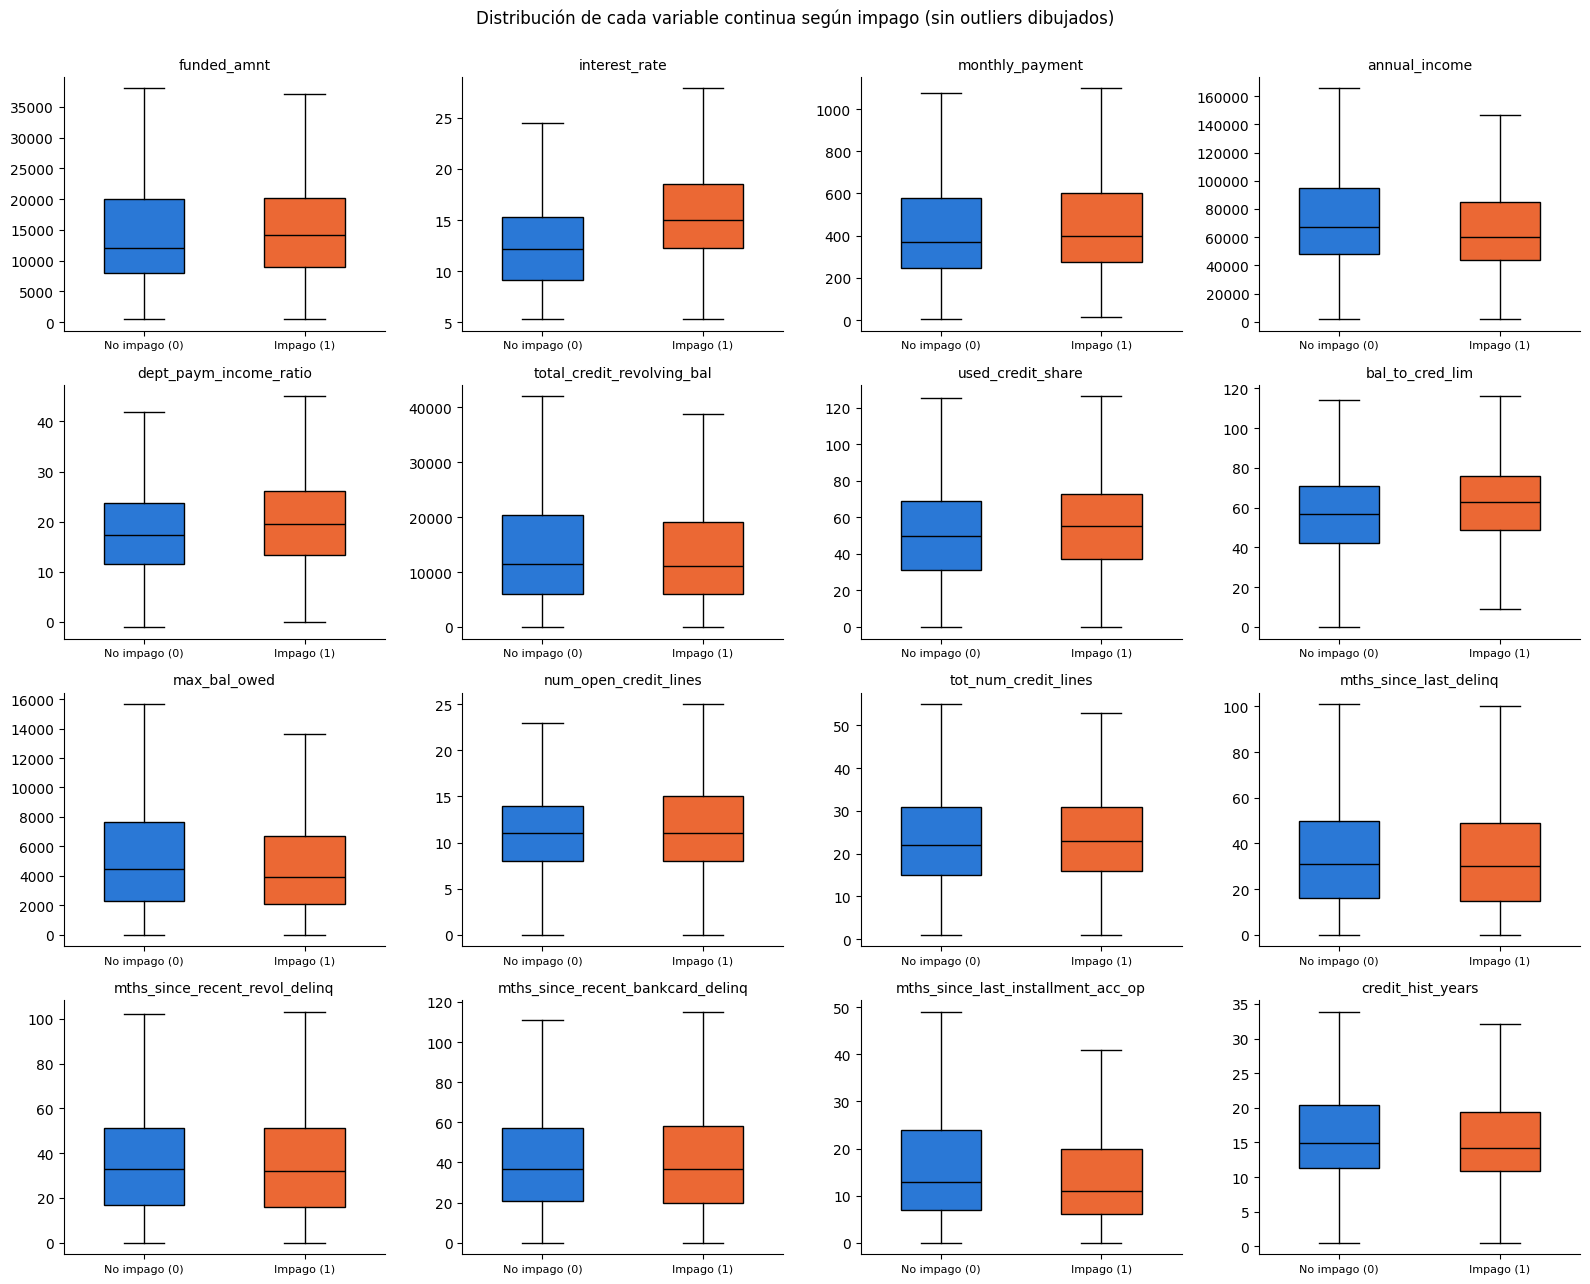

In [14]:
# Un boxplot por variable continua: no impago (azul) vs impago (naranja)
fig, axes = rejilla(len(continuas), ncols=4, ancho=4, alto=3.2)
for ax, col in zip(axes, continuas):
    grupos = [df.loc[df["impago"] == k, col].dropna() for k in (0, 1)]   # boxplot no admite NaN
    bp = ax.boxplot(grupos, showfliers=False, patch_artist=True, widths=0.5,
                    medianprops={"color": "black"})
    for caja, color in zip(bp["boxes"], (COLOR_NO_IMPAGO, COLOR_IMPAGO)):
        caja.set_facecolor(color)
    ax.set_xticks([1, 2], ["No impago (0)", "Impago (1)"], fontsize=8)
    ax.set_title(col, fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Distribución de cada variable continua según impago (sin outliers dibujados)", y=1.0)
fig.tight_layout()
plt.show()

### 4.4 Tasa de impago por deciles de cada variable continua

Ahora le damos la vuelta: en vez de mirar la variable según el target, miramos **el target según la variable**. Cortamos cada continua en 10 tramos con el mismo número de préstamos (deciles) y calculamos la tasa de impago de cada tramo. Es el análisis clásico de scoring y la antesala del WoE/IV: muestra directamente **P(impago | tramo)**, que es lo que el modelo de PD tiene que aprender.

**Cómo se lee:**
- **Barras que suben (o bajan) de forma ordenada de izquierda a derecha** → relación **monótona**: la variable es buena candidata y entra bien en una regresión logística (tal cual, en log o en tramos).
- **Barras planas, todas cerca de la línea discontinua** → la variable por sí sola apenas discrimina.
- **Forma de U o saltos** → relación no lineal: habrá que discretizar o transformar.
- **La barra "missing"** muestra la tasa de los préstamos sin dato. Si es distinta de las demás, el nulo es informativo y merece su propio flag.

Las etiquetas del eje X son los límites de cada tramo. En variables con muchos valores repetidos salen menos de 10 tramos.

**Qué se observa:**
- **`interest_rate`: la relación más fuerte y monótona** de todo el dataset, del **3% en el primer decil al 26% en el último**.
- **Monótonas crecientes, más suaves**: `dept_paym_income_ratio` (10% → 18%), `used_credit_share` (9% → 16%), `bal_to_cred_lim` (7% → 13%), `funded_amnt` y `monthly_payment` (9–10% → 14–15%).
- **Monótona decreciente**: `annual_income` (16% → 9%): a más ingresos, menos impago. También `credit_hist_years`, de forma muy suave (14–15% → 11%).
- **Prácticamente planas**: `total_credit_revolving_bal`, `num_open_credit_lines`, `tot_num_credit_lines` y las `mths_since_*_delinq`.
- **El grupo "missing" del bloque del 40% (`bal_to_cred_lim`, `max_bal_owed`, `mths_since_last_installment_acc_op`) tiene un 17% de impago**, claramente por encima de cualquier decil con dato (7–13%). Como vimos en 3.5, estos nulos son préstamos **antiguos** (hasta 2015), de antes de que Lending Club recogiera esos campos. Los préstamos antiguos han tenido tiempo de vencer y de impagar, y los recientes todavía no (ver `issue_date_year` en 4.6). Por tanto, este 17% refleja sobre todo **la antigüedad del préstamo, no el perfil del cliente**. Hay que tenerlo presente para no sobrevalorar estas variables.
- **En las `mths_since_*_delinq`, "missing" (= nunca ha tenido un retraso) está en el 12–13%**, solo algo por debajo de los clientes con retrasos (13–15%). La diferencia existe pero es pequeña: haber tenido un retraso hace tiempo apenas cambia el riesgo.

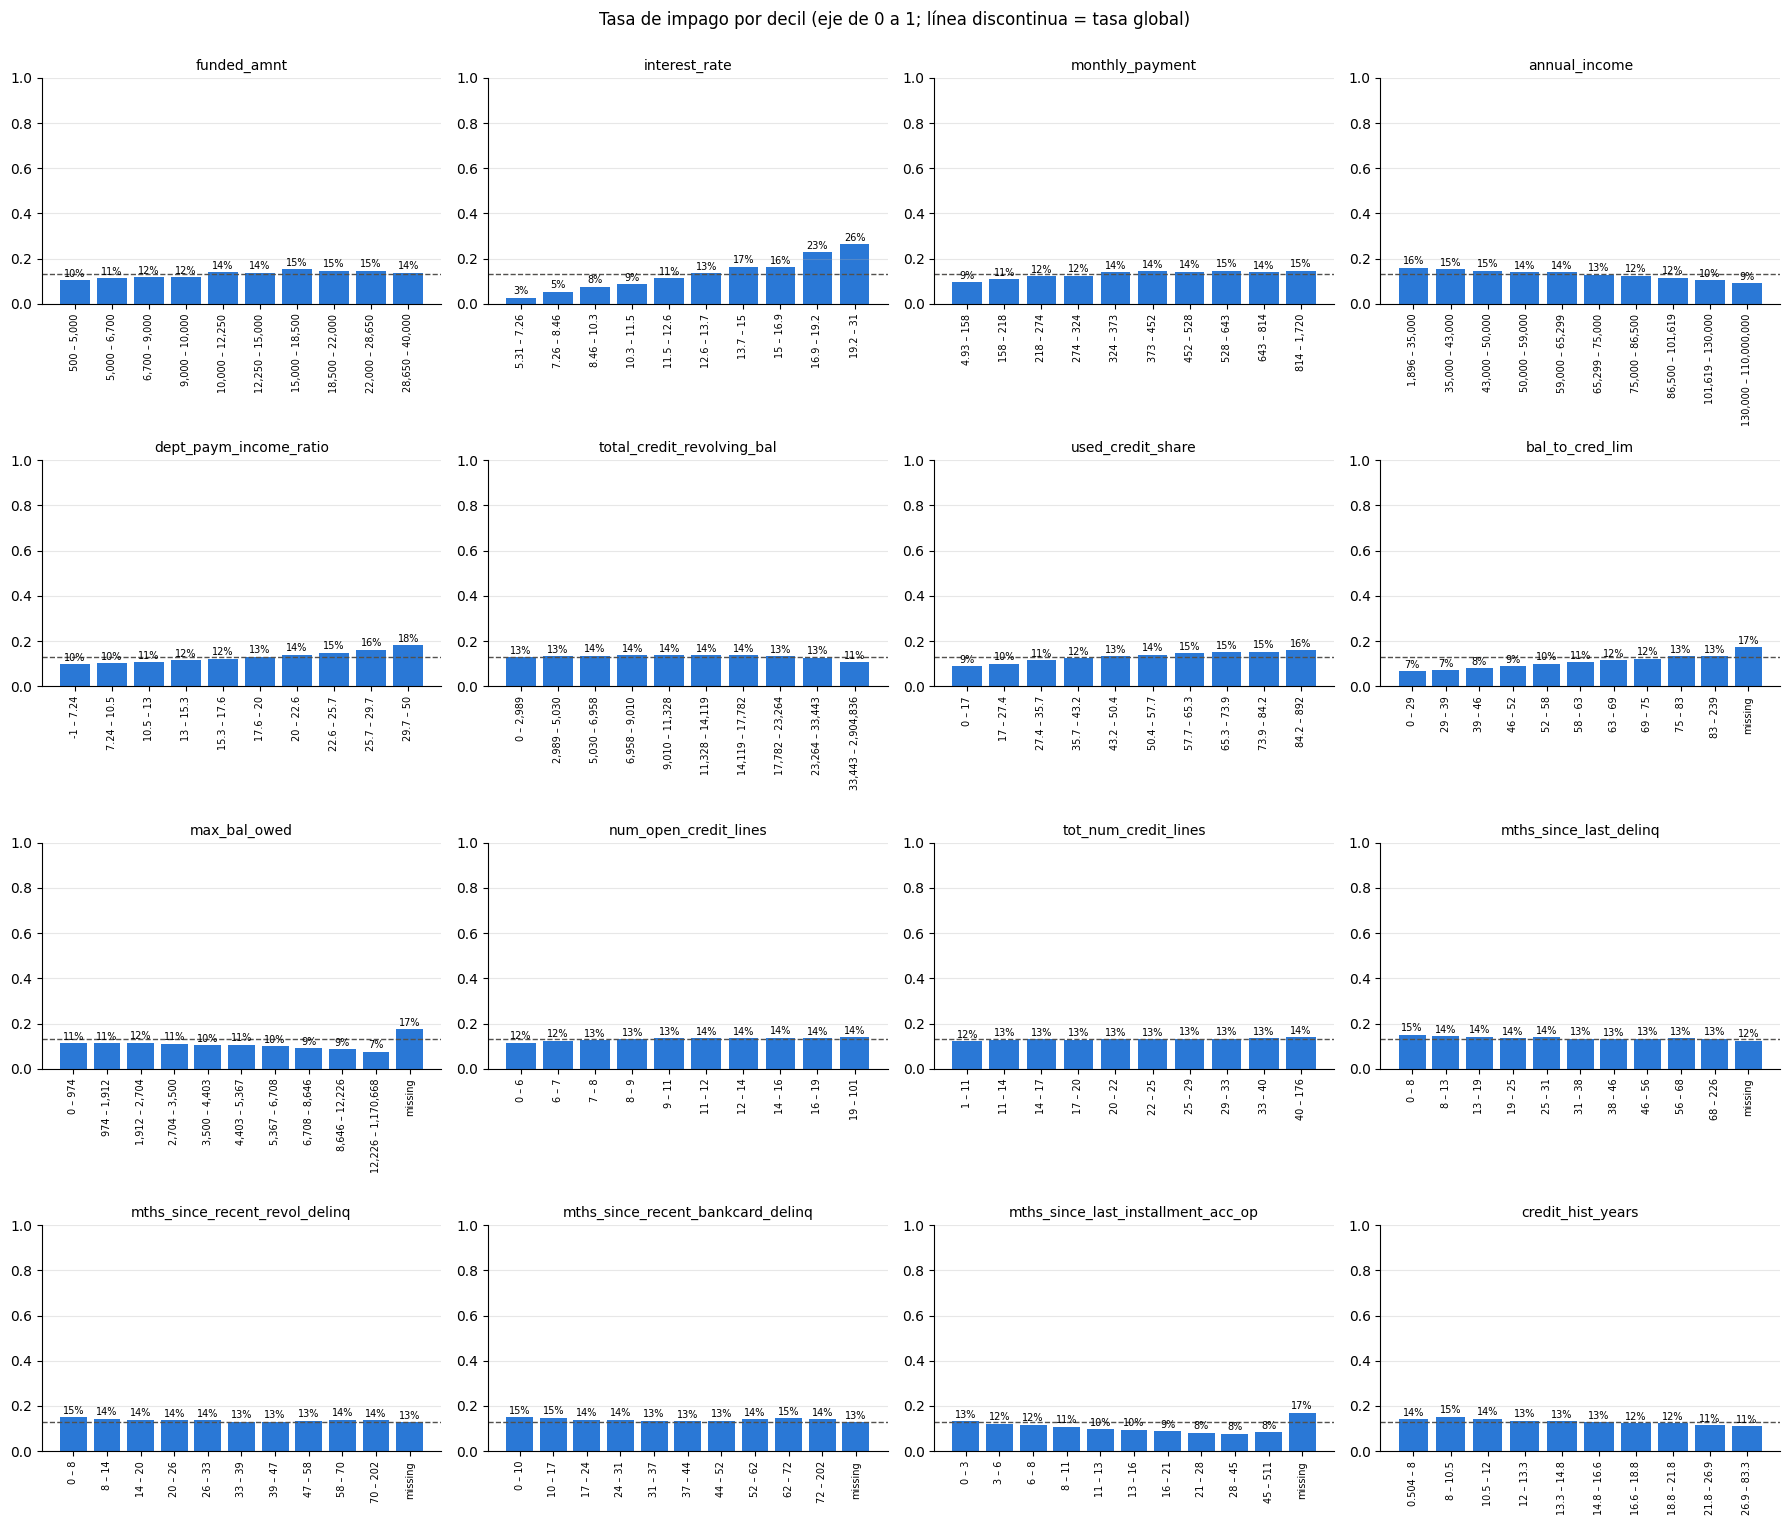

In [15]:
# Tasa de impago por decil de cada continua (los nulos, en la barra "missing")
fig, axes = rejilla(len(continuas), ncols=4, ancho=4.5, alto=3.8)
for ax, col in zip(axes, continuas):
    plot_tasa(ax, tabla_tasa(tramos(col)), col, mostrar_n=False)   # todos los deciles tienen ~10%
fig.suptitle("Tasa de impago por decil (eje de 0 a 1; línea discontinua = tasa global)", y=1.0)
fig.tight_layout()
plt.show()

### 4.5 Tasa de impago por valor de los conteos

Los conteos (número de retrasos, de consultas, de cuentas abiertas recientemente...) tienen pocos valores y la mayoría de préstamos está en 0. Un boxplot no sirve (la caja colapsa en 0) y los deciles tampoco (casi todos los cortes caerían en el mismo valor). Lo natural es calcular la **tasa de impago para cada valor**: 0, 1, 2... agrupando la cola en "k+" para que el último grupo tenga suficientes préstamos.

**Cómo se lee**: igual que los deciles, pero aquí cada grupo tiene un tamaño distinto. Debajo de cada barra aparece el **número de préstamos (en miles)**: una tasa calculada con pocos miles de préstamos es menos fiable que una con cientos de miles.

**Qué se observa:**
- **`num_inq_in_6mths` (consultas de crédito en los últimos 6 meses) es el conteo más claro**: del **11% con 0 consultas al 26% con 5 o más**, monótono. Un cliente que está pidiendo crédito en muchos sitios a la vez es una señal de riesgo clásica.
- **Crecientes y monótonas**: todas las de actividad reciente de buró (`num_inq`, `num_open_trades_in_6mths`, `num_installment_acc_op_*`, `num_rev_trades_op_*`), aproximadamente del 7–9% con 0 al 16–18% en la cola. Abrir muchas cuentas en poco tiempo = más riesgo.
- **Su grupo "missing" tiene un 17%**: es el mismo bloque del 40% de nulos y el mismo efecto que en 4.4 (préstamos antiguos, ya maduros).
- **Retrasos y registros públicos** (`num_30+_delinq_in_2yrs`, `num_derogatory_pub_rec`): crecen, pero poco (13% → 16–18%), y casi toda la cartera está en 0. Lending Club ya filtra a los clientes con mal historial, así que entre los que reciben un préstamo esta variable discrimina menos de lo que cabría esperar.
- **`emp_length_num` es plana** (12–14% en todos los años de antigüedad). Lo único que destaca es **"missing" (16%)**: no informar el empleo sí es una señal de riesgo, más que los años de antigüedad.

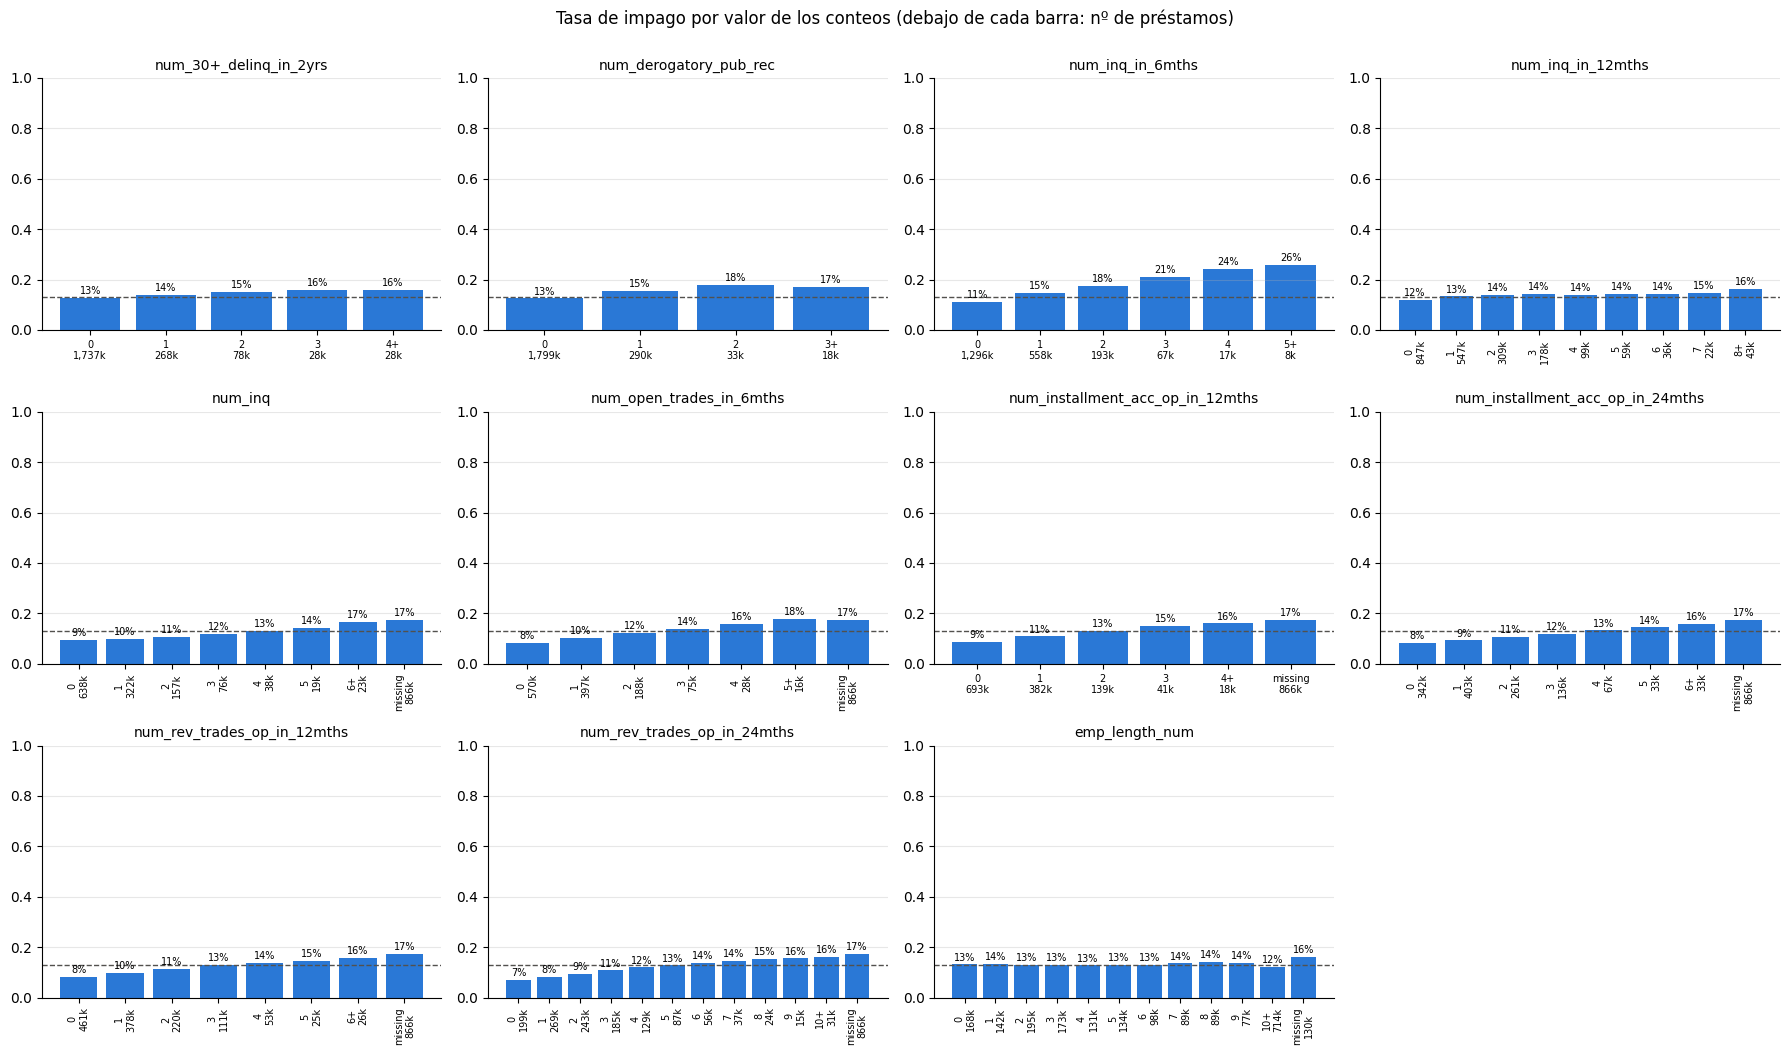

In [16]:
# Tasa de impago por valor de cada conteo (cola agrupada en "k+", nulos en "missing")
fig, axes = rejilla(len(conteos), ncols=4, ancho=4.5, alto=3.5)
for ax, (col, k) in zip(axes, conteos.items()):
    plot_tasa(ax, tabla_tasa(con_tope(col, k)), col)
fig.suptitle("Tasa de impago por valor de los conteos (debajo de cada barra: nº de préstamos)", y=1.0)
fig.tight_layout()
plt.show()

### 4.6 Tasa de impago de las variables categóricas

Una barra por categoría con su tasa de impago, el **eje Y de 0 a 1**, la línea de la tasa global y el **número de préstamos debajo de cada barra**.

**Orden de las barras**: las variables con orden natural (`loan_term_months`, `issue_date_year`, `issue_date_month`) se muestran en su orden; las nominales (sin orden: vivienda, finalidad, estado...) se ordenan **de mayor a menor tasa**, para ver de un vistazo qué categorías son más arriesgadas.

`addr_state` (51 estados) y `emp_title_clean` (más de 200 profesiones) van en figuras aparte por tamaño. En `addr_state` no se escriben las tasas ni los tamaños porque no caben; en `emp_title_clean` mostramos solo las 20 profesiones más frecuentes más "missing" y "otros".

**Qué se observa:**
- **`loan_term_months`**: 60 meses → **18%** frente a 11% a 36 meses. Un plazo más largo da más tiempo para que algo vaya mal y suele elegirse para importes grandes o cuotas ajustadas.
- **`verification_status`**: Verified 17%, Source Verified 13%, Not Verified 9%. **Parece contraintuitivo** (¿verificar los ingresos aumenta el riesgo?), pero tiene explicación: Lending Club verifica sobre todo a los solicitantes que le parecen más arriesgados. La variable refleja **a quién decide verificar**, no el efecto de verificar.
- **`home_ownership_status`**: alquiler (RENT) 15% > propietario (OWN) 13% > hipoteca (MORTGAGE) 11,5%. OTHER solo tiene unos 1.000 préstamos, así que su tasa es poco fiable.
- **`loan_purpose`**: las finalidades de más riesgo son small_business (20%) y educational (21%, pero con muy pocos préstamos); las de menos, car y credit_card (10–11%). La mayor categoría, debt_consolidation (1,2 millones), está en la media.
- **`region_code` e `issue_date_month`: casi planas** (12–14%). Aportan poco.
- **`addr_state`**: la mayoría de estados está entre el 10% y el 16%. **La barra más alta, IA (21%), solo tiene 14 préstamos**: es ruido. Este es justo el peligro de las categorías pequeñas, que habrá que agrupar o suavizar al codificar (en train).
- **`emp_title_clean`**: conductores (driver, truck driver) 17% y "missing" 15% en lo alto; puestos directivos (vice president, director) 9–10% en lo bajo.

**El hallazgo más importante: `issue_date_year`.**
- Los primeros años (2007–2008) tienen tasas altas (21–27%, con pocos préstamos y con la crisis financiera).
- 2009–2016 se mantienen en torno al 14–18%.
- **2017 cae al 10% y 2018 al 3%.**

Los préstamos de 2017–2018 no son mejores: es que **aún no han tenido tiempo de impagar**. Son **añadas inmaduras** (en estadística, censura por la derecha). El dato se observa en una fecha fija; un préstamo a 36 o 60 meses concedido en 2018 apenas lleva unos meses vivo, y la mayoría de impagos ocurren más adelante.

Este mismo efecto explica otras dos variables:
- **`disbursement_method`**: DirectPay tiene un 2% de impago porque casi todos sus préstamos son de 2018 (66.000 de 73.000). No es que DirectPay sea más seguro.
- **`initial_list_status`**: la categoría `f` (16%) domina en los préstamos antiguos (100% hasta 2011) y la `w` (12%) en los recientes.

Y también el grupo "missing" del bloque del 40%, como vimos en 4.4 y 4.5.

**Por qué importa para el ECL**: si el modelo de PD aprende que "reciente = seguro" (a través del año o de variables relacionadas con la fecha), infraestimará la PD de los préstamos recientes. Y como la pérdida real del test también se calcula con préstamos inmaduros, este efecto será clave al elegir las variables y al calibrar el margen conservador.

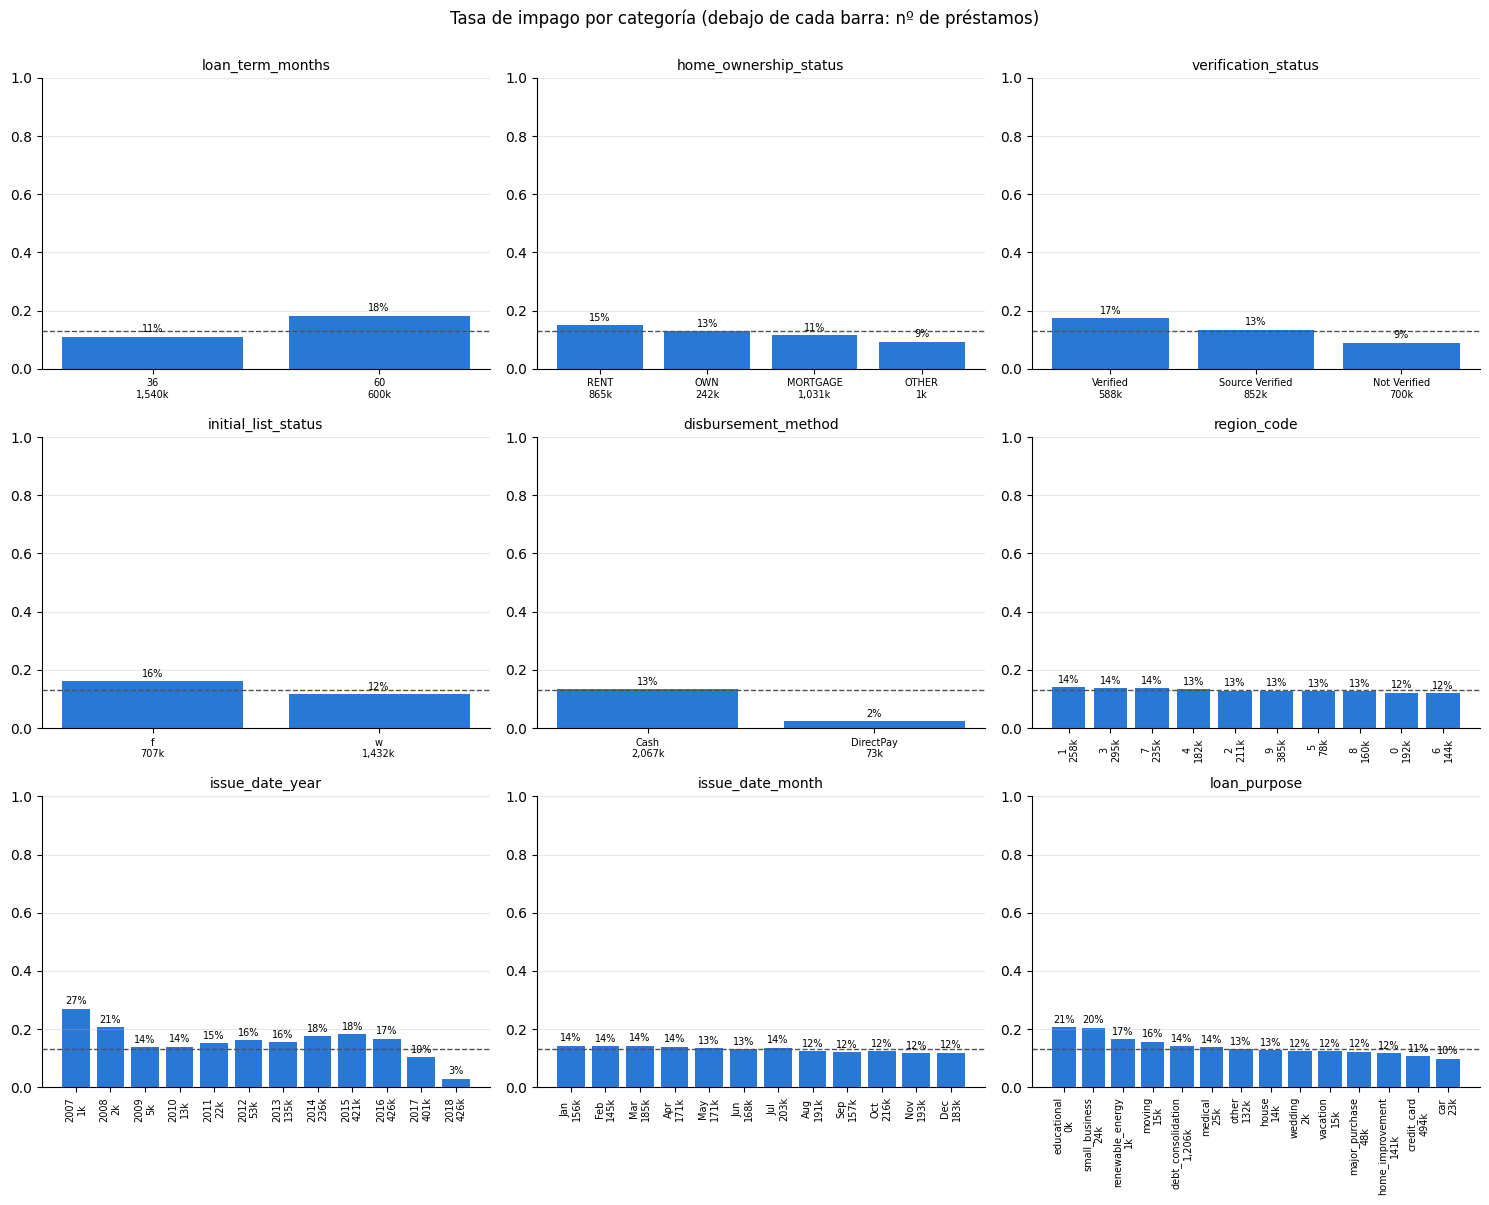

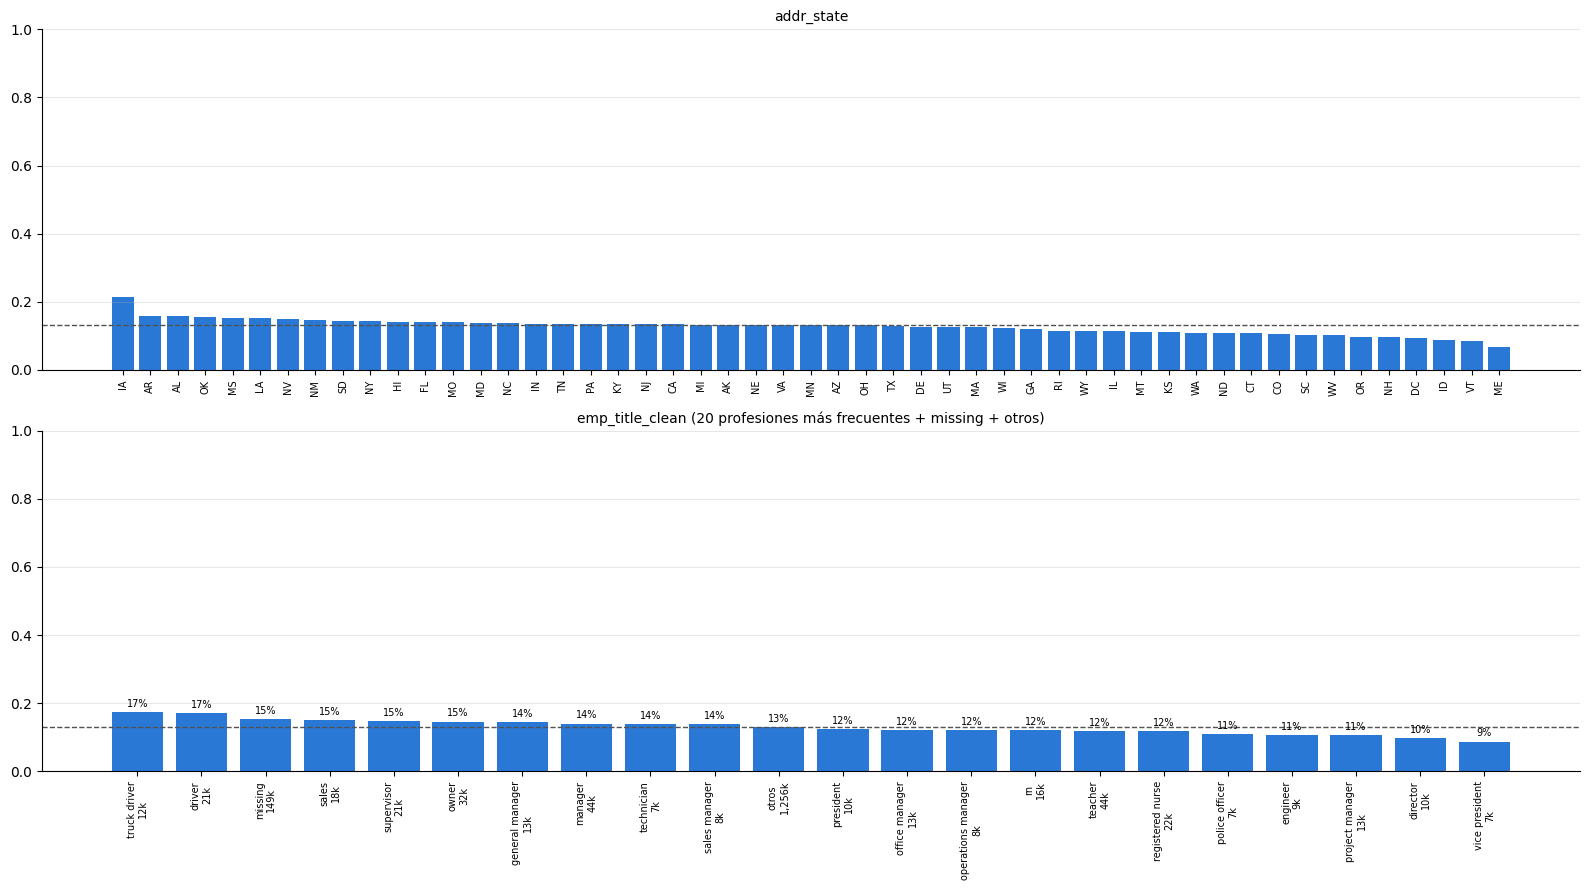

In [17]:
# Orden natural para las ordinales; las nominales se ordenan de mayor a menor tasa
ordinales = ["loan_term_months", "issue_date_year", "issue_date_month"]
meses = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

pequenas = [c for c in categoricas if c not in ("addr_state", "emp_title_clean")]
fig, axes = rejilla(len(pequenas), ncols=3, ancho=5, alto=4)
for ax, col in zip(axes, pequenas):
    t = tabla_tasa(df[col])
    if col == "issue_date_month":
        t = t.reindex(meses)   # orden de calendario, no alfabético
    elif col not in ordinales:
        t = t.sort_values("tasa_impago", ascending=False)
    plot_tasa(ax, t, col)
fig.suptitle("Tasa de impago por categoría (debajo de cada barra: nº de préstamos)", y=1.0)
fig.tight_layout()
plt.show()

# addr_state (51 estados) y emp_title_clean (top 20 + missing + otros) en figuras propias
fig, axes = plt.subplots(2, 1, figsize=(16, 9))
plot_tasa(axes[0], tabla_tasa(df["addr_state"]).sort_values("tasa_impago", ascending=False),
          "addr_state", etiquetas=False, mostrar_n=False)
t_emp = tabla_tasa(df["emp_title_clean"]).sort_values("n", ascending=False)
plot_tasa(axes[1], t_emp.head(22).sort_values("tasa_impago", ascending=False),
          "emp_title_clean (20 profesiones más frecuentes + missing + otros)")
fig.tight_layout()
plt.show()

### 4.7 Ranking de variables por Information Value (IV)

Hemos visto unos 40 gráficos. Para resumirlos en un único número por variable usamos el **Information Value**, la medida estándar en scoring del poder discriminante de una variable agrupada en tramos.

**Fórmula** (por cada grupo g de la variable):
- %buenos_g = no impagados del grupo / total de no impagados
- %malos_g = impagados del grupo / total de impagados
- WoE_g = ln(%buenos_g / %malos_g)
- **IV = suma sobre los grupos de (%buenos_g − %malos_g) × WoE_g**

Si la variable no discrimina, cada grupo tiene la misma proporción de buenos que de malos, WoE ≈ 0 e IV ≈ 0. Cuanto más distinta es la composición de los grupos, mayor es el IV.

**Escala habitual**: < 0,02 sin poder predictivo · 0,02–0,1 débil · 0,1–0,3 medio · 0,3–0,5 fuerte · > 0,5 sospechoso (posible leakage).

Usamos los mismos grupos que en los gráficos: deciles para las continuas, valores con tope para los conteos y categorías para las categóricas, siempre con "missing" como grupo propio. El IV depende de cómo se agrupe, así que es una guía para ordenar, no un valor exacto. Las columnas `tasa_min` y `tasa_max` dan el rango de tasas de impago (en %) entre los grupos de cada variable.

**Qué se observa** (hay que leer el ranking con lo aprendido en 4.4–4.6):
- **`interest_rate` (IV ≈ 0,45, fuerte)**: la mejor variable, como ya se veía en los gráficos.
- **`issue_date_year` (IV ≈ 0,37) es la segunda, pero por el motivo equivocado**: su poder viene casi todo de la inmadurez de 2017–2018, no del riesgo del cliente. Un modelo que la use aprendería "reciente = seguro".
- **Las variables del bloque del 40% de nulos (IV 0,10–0,14)**: `num_rev_trades_op_*`, `bal_to_cred_lim`, `num_open_trades_in_6mths`, `num_installment_acc_op_*`, `max_bal_owed`, `num_inq`. Su `tasa_max` es casi siempre 17,4%, que es exactamente la tasa del grupo "missing". Parte de su IV viene de la antigüedad del préstamo, aunque también tienen relación monótona dentro de los préstamos con dato (4.5).
- **Débiles pero útiles (0,02–0,1)**: `verification_status`, `loan_term_months`, `num_inq_in_6mths`, `dept_paym_income_ratio`, `used_credit_share`, `annual_income`, `loan_purpose`, `home_ownership_status`, `funded_amnt`... Por separado aportan poco, pero en un modelo multivariante pueden sumar.
- **`disbursement_method` (0,06) e `initial_list_status` (0,03)** también están contaminadas por la fecha (4.6).
- **Sin poder predictivo (< 0,02)**: `region_code`, `issue_date_month`, `tot_num_credit_lines`, `num_open_credit_lines`, `total_credit_revolving_bal`, las `mths_since_*_delinq`, `emp_length_num`... Son candidatas a quedar fuera del modelo o a entrar solo con su flag de nulo.

Ninguna variable pasa de 0,5, así que no hay indicios de leakage entre las variables de originación.

In [18]:
def information_value(t):
    """IV = suma de (%no_impago - %impago) * ln(%no_impago / %impago) sobre los grupos."""
    buenos = (t["n"] - t["n_impagos"]) / (t["n"] - t["n_impagos"]).sum()
    malos = t["n_impagos"] / t["n_impagos"].sum()
    buenos, malos = buenos.clip(lower=1e-6), malos.clip(lower=1e-6)   # evita log(0) en grupos vacíos
    return ((buenos - malos) * np.log(buenos / malos)).sum()

# Mismos grupos que en los gráficos: deciles, conteos con tope y categorías
claves = ([tramos(c) for c in continuas] + [con_tope(c, k) for c, k in conteos.items()]
          + [df[c] for c in categoricas])
ranking = pd.DataFrame(
    [(c.name, information_value(t := tabla_tasa(c)), t["tasa_impago"].min(), t["tasa_impago"].max())
     for c in claves],
    columns=["variable", "IV", "tasa_min", "tasa_max"]).set_index("variable")
ranking[["tasa_min", "tasa_max"]] = (ranking[["tasa_min", "tasa_max"]] * 100).round(1)   # en %
ranking.sort_values("IV", ascending=False).round(3)

,IV,tasa_min,tasa_max
variable,,,
interest_rate,0.448,2.7,26.4
issue_date_year,0.374,2.9,27.0
num_rev_trades_op_in_24mths,0.137,6.9,17.4
bal_to_cred_lim,0.131,6.7,17.4
num_open_trades_in_6mths,0.122,8.4,17.9
num_rev_trades_op_in_12mths,0.122,8.1,17.4
num_installment_acc_op_in_12mths,0.117,8.7,17.4
num_installment_acc_op_in_24mths,0.117,8.3,17.4
mths_since_last_installment_acc_op,0.111,7.7,17.1


### 4.8 Correlación de Spearman entre variables numéricas (multicolinealidad)

Hasta aquí hemos mirado cada variable **frente al target**. Falta una pregunta que el análisis univariante no responde: **¿qué variables dicen lo mismo entre sí?**

**Por qué importa (multicolinealidad):** si dos variables muy correlacionadas entran juntas en una regresión logística, el modelo no sabe a cuál atribuir el efecto. Los coeficientes se vuelven inestables (cambian mucho con pequeñas variaciones de los datos) y pueden salir con el signo contrario al esperado, lo que los hace ininterpretables. No suele empeorar mucho la predicción, pero sí la explicabilidad, que en un modelo regulatorio es clave.

**Por qué Spearman y no Pearson:** Spearman calcula la correlación sobre los **rangos** (posiciones ordenadas) en lugar de sobre los valores. Así no le afectan las colas largas (un ingreso de 110 millones es simplemente "el más alto") y capta cualquier relación **monótona**, aunque no sea lineal.

**Detalles:**
- Calculamos sobre una **muestra aleatoria de 200.000 préstamos** solo por velocidad: con nulos, Spearman se calcula pareja a pareja y es lento sobre 2,1 millones de filas. Con 200.000 filas el error en cada ρ es menor de 0,01.
- En las variables con nulos, cada correlación usa solo los préstamos que tienen dato en las dos variables.
- **No usamos p-valores**: con tantos datos, cualquier correlación distinta de cero sale significativa. Nos fijamos en el **tamaño** de ρ.
- **Umbral de referencia: |ρ| > 0,7** indica variables redundantes. En el mapa solo se escriben los valores con |ρ| ≥ 0,5 para no saturar.

**Cómo se lee:** naranja = correlación positiva, azul = negativa, gris = sin relación. La diagonal (cada variable consigo misma) vale 1.

**Qué se observa** (parejas con |ρ| > 0,7, en la tabla de debajo del mapa):
- **`funded_amnt` – `monthly_payment` (0,96)**: prácticamente la misma información. La cuota es el importe repartido según el plazo y el tipo de interés.
- **Las tres `mths_since_*_delinq` entre sí (0,76–0,89)** y con **`num_30+_delinq_in_2yrs` (−0,72 a −0,82)**: todas miden lo mismo, el historial de retrasos. La relación con el conteo es negativa y lógica: quien se retrasó hace poco tiene más retrasos en los últimos 2 años.
- **`mths_since_last_installment_acc_op` – `num_installment_acc_op_in_12mths` / `_24mths` (−0,86 / −0,77)**: si abriste un préstamo a plazos hace poco, tienes más préstamos abiertos en el último año.
- **Las parejas `_12mths` / `_24mths`** (`num_rev_trades_op` 0,75 y `num_installment_acc_op` 0,70): la ventana de 24 meses contiene a la de 12.
- **`total_credit_revolving_bal` – `max_bal_owed` (0,80)** y **`num_open_credit_lines` – `tot_num_credit_lines` (0,71)**.
- Por debajo del umbral, pero a tener en cuenta: `used_credit_share` – `bal_to_cred_lim` (0,67) y `num_inq_in_6mths` – `num_inq_in_12mths` (0,62).
- **`interest_rate`, `dept_paym_income_ratio`, `annual_income` y `loan_term_months` no tienen ninguna correlación fuerte** con el resto: aportan información propia.

Conclusión: hay varios **grupos de variables redundantes**. Más adelante, en la selección de variables (con train), conviene quedarse con una por grupo (la de más IV o más sentido de negocio) o combinarlas.

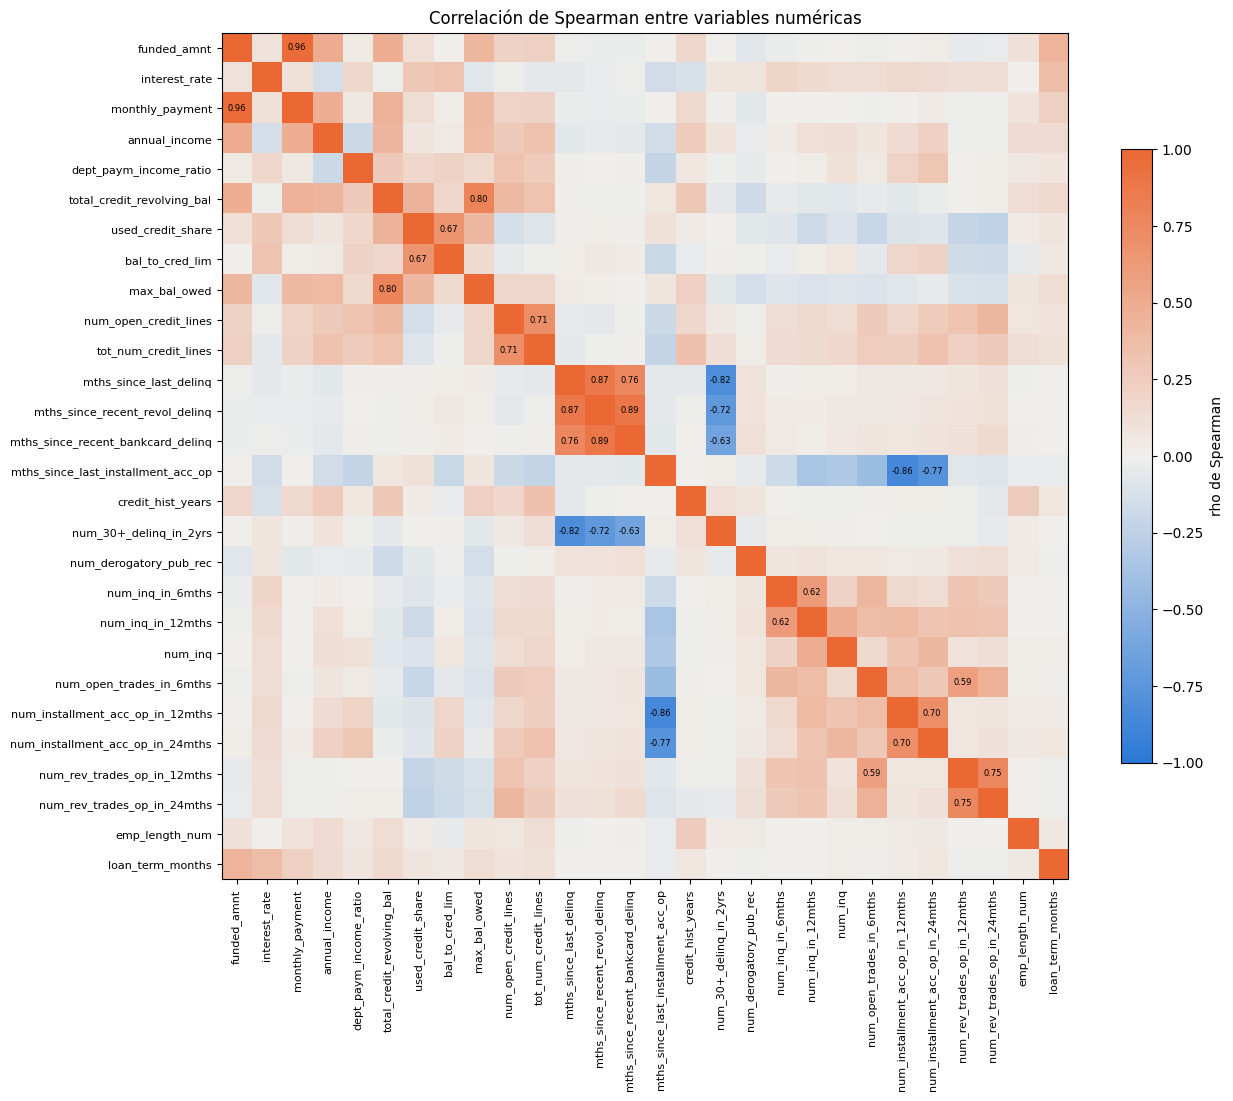

,variable_1,variable_2,rho
1,funded_amnt,monthly_payment,0.96
258,mths_since_recent_revol_delinq,mths_since_recent_bankcard_delinq,0.89
242,mths_since_last_delinq,mths_since_recent_revol_delinq,0.87
294,mths_since_last_installment_acc_op,num_installment_acc_op_in_12mths,-0.86
246,mths_since_last_delinq,num_30+_delinq_in_2yrs,-0.82
127,total_credit_revolving_bal,max_bal_owed,0.80
295,mths_since_last_installment_acc_op,num_installment_acc_op_in_24mths,-0.77
243,mths_since_last_delinq,mths_since_recent_bankcard_delinq,0.76
372,num_rev_trades_op_in_12mths,num_rev_trades_op_in_24mths,0.75
261,mths_since_recent_revol_delinq,num_30+_delinq_in_2yrs,-0.72


In [19]:
from matplotlib.colors import LinearSegmentedColormap

# Numéricas del EDA (sin códigos ni fechas); muestra de 200.000 filas solo por velocidad
num_cols = continuas + list(conteos) + ["loan_term_months"]
corr = df[num_cols].sample(200_000, random_state=42).corr(method="spearman")

# Mapa de calor divergente: azul = correlación negativa, gris = 0, naranja = positiva
cmap_div = LinearSegmentedColormap.from_list("div", [COLOR_NO_IMPAGO, "#f0efec", COLOR_IMPAGO])
fig, ax = plt.subplots(figsize=(13, 11))
im = ax.imshow(corr, cmap=cmap_div, vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols)), num_cols, rotation=90, fontsize=8)
ax.set_yticks(range(len(num_cols)), num_cols, fontsize=8)
for i in range(len(num_cols)):          # solo escribimos las correlaciones relevantes (|rho| >= 0,5)
    for j in range(len(num_cols)):
        if i != j and abs(corr.iloc[i, j]) >= 0.5:
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6)
fig.colorbar(im, ax=ax, shrink=0.7, label="rho de Spearman")
ax.set_title("Correlación de Spearman entre variables numéricas")
fig.tight_layout()
plt.show()

# Parejas redundantes: |rho| > 0,7 (triángulo superior para no repetir cada pareja)
superior = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
parejas = superior.stack().rename("rho").reset_index()
parejas.columns = ["variable_1", "variable_2", "rho"]
parejas = parejas[parejas["rho"].abs() > 0.7].sort_values("rho", key=abs, ascending=False)
parejas.round(2)

### Conclusiones del EDA de relación con el impago

**Variables con más poder discriminante** (candidatas principales para el modelo de PD):
1. `interest_rate`: con diferencia la mejor (IV ≈ 0,45, de 3% a 26%), monótona.
2. Actividad reciente de buró: consultas (`num_inq_in_6mths`, `num_inq`) y cuentas abiertas recientemente (`num_open_trades_in_6mths`, `num_*_op_in_*mths`). Monótonas crecientes.
3. Endeudamiento y uso del crédito: `dept_paym_income_ratio`, `bal_to_cred_lim`, `used_credit_share`. Monótonas crecientes.
4. `loan_term_months`, `verification_status`, `annual_income` (decreciente), `home_ownership_status`, `loan_purpose`.

**Variables casi sin poder discriminante por sí solas**: `region_code`, `issue_date_month`, `num_open_credit_lines`, `tot_num_credit_lines`, `total_credit_revolving_bal`, `emp_length_num` (salvo su nulo) y las `mths_since_*_delinq`.

**Redundancias** (4.8). Grupos de numéricas que dicen casi lo mismo (|ρ| > 0,7):
- `funded_amnt` – `monthly_payment`;
- las `mths_since_*_delinq` con `num_30+_delinq_in_2yrs`;
- las ventanas de 12 y 24 meses de cuentas abiertas, junto con `mths_since_last_installment_acc_op`;
- `total_credit_revolving_bal` – `max_bal_owed`;
- `num_open_credit_lines` – `tot_num_credit_lines`.

Habrá que quedarse con una por grupo o combinarlas. Entre las categóricas, la única relación clara que hemos visto es la de `initial_list_status` y `disbursement_method` con la fecha de concesión (4.6).

**Nulos informativos** (merecen un flag propio):
- `emp_length` / `emp_title` sin informar: 15–16% de impago frente al 13% global.
- El bloque del 40% equivale a "préstamo de 2015 o anterior" (confirmado). Su flag capturaría la antigüedad del préstamo, no el riesgo del cliente.

**El problema principal: la inmadurez de las añadas recientes.** Los préstamos de 2017–2018 tienen tasas del 10% y del 3% porque aún no han tenido tiempo de impagar. Este efecto contamina `issue_date_year` y todo lo que está correlacionado con la fecha: `disbursement_method`, `initial_list_status` y los nulos del bloque del 40%. Se trata en 5.3 con variables de madurez.

**Recordatorio**: todo esto es descriptivo y se ha hecho sobre el dataset completo. Los cortes de tramos, la agrupación de categorías pequeñas (como IA en `addr_state`), los topes de outliers, los encodings y la selección de variables se ajustarán **solo con train** cuando construyamos el pipeline.

## 5. Preparación de los datos

Esta sección deja los datos listos para los modelos: corrige los valores imposibles, divide la cartera en train / validación / test y crea las variables nuevas. Todo son **reglas fijas, fila a fila**, que no aprenden nada de los datos, así que se pueden aplicar igual a las tres partes sin riesgo de leakage.

Lo que **sí aprende de los datos** (topes de outliers, valores de imputación, encodings) se ajusta solo con train y está en `02_modelo_pd.ipynb`, dentro del pipeline de cada modelo.

**Importante: no se borra ninguna fila.** El ECL se calcula sobre **todos** los préstamos de la cartera, y quitar préstamos sesgaría la provisión: un préstamo con un dato mal capturado sigue existiendo y puede impagar. Lo que se corrige es el **valor**, no la fila.

### 5.1 Valores imposibles → nulo (antes del split)

En el `describe` vimos que `dept_paym_income_ratio` (DTI, pagos de deuda / ingresos) tiene un mínimo de **−1**. Un ratio de deuda sobre ingresos no puede ser negativo, así que ese −1 es casi seguro un código de "sin dato" de la fuente. Lo convertimos en **NaN**: a partir de aquí se tratará igual que cualquier otro nulo (imputación + flag, más adelante).

¿Por qué NaN y no 0 o la mediana? Porque 0 sería afirmar que el cliente no tiene deudas, y la mediana sería inventarse un valor; además, la mediana aprende de los datos y tendría que calcularse en train. Convertir a NaN es una **regla fija** (no aprende nada), por lo que es legítimo hacerlo antes del split.

Es un solo préstamo, así que el impacto es mínimo, pero lo correcto es tratarlo bien.

**Comprobaciones**: que ya no queda ningún DTI negativo y que los nulos han aumentado exactamente en el número de valores corregidos (ni más ni menos).

In [20]:
# Valor imposible: un ratio deuda/ingresos no puede ser negativo -> -1 es un código de "sin dato"
dti_neg = df["dept_paym_income_ratio"] < 0
print(f"Préstamos con DTI negativo: {dti_neg.sum()} "
      f"(valores: {df.loc[dti_neg, 'dept_paym_income_ratio'].unique()})")
n_null_antes = df["dept_paym_income_ratio"].isna().sum()

df.loc[dti_neg, "dept_paym_income_ratio"] = np.nan

# Comprobación: ya no hay negativos y los nulos han aumentado exactamente en los valores corregidos
assert (df["dept_paym_income_ratio"] < 0).sum() == 0
assert df["dept_paym_income_ratio"].isna().sum() == n_null_antes + dti_neg.sum()
print(f"Nulos en DTI: {n_null_antes} -> {df['dept_paym_income_ratio'].isna().sum()}")

Préstamos con DTI negativo: 1 (valores: [-1.])
Nulos en DTI: 0 -> 1


### 5.2 Split train / validación / test

A partir de aquí todo lo que aprenda de los datos se ajustará con train, así que dividimos ya la cartera en tres partes:

| Parte | % del total | Para qué se usa |
|---|---|---|
| **train** | 64% | Ajustar todo: preprocesado (percentiles, imputaciones, encodings) y los modelos de PD, EAD y LGD |
| **validación** | 16% | Elegir hiperparámetros y, sobre todo, **calibrar el margen conservador** del ECL (en `03_ead_lgd_ecl.ipynb`) sin tocar el test |
| **test** | 20% | Evaluación final, una sola vez, como si fuera la cartera nueva que nos pide el Comité de Riesgos |

Se hace en dos pasos con `train_test_split`: primero se aparta el 20% de test, y del 80% restante se aparta un 20% para validación (0,8 × 0,2 = 16% del total).

**Decisiones:**
- **`stratify=impago`**: garantiza que las tres partes tengan la misma tasa de impago (13,07%). Con 2,1 millones de préstamos un split aleatorio daría casi lo mismo, pero estratificar lo asegura y no cuesta nada.
- **`random_state=42`**: fija la semilla para que el split sea reproducible (cada vez que se ejecute el notebook salen exactamente los mismos préstamos en cada parte).
- **Split aleatorio, no temporal**: no hay una fecha de corte definida para la cartera a evaluar. El efecto de las añadas inmaduras se trata con las variables de madurez (5.3).
- Se dividen las **filas completas de `df`** (incluidas las variables de performance), porque las necesitaremos para construir los targets de EAD y LGD en cada parte. La separación entre predictores y targets se hará después.

**Comprobaciones**: que las tres partes suman el total y no comparten ningún préstamo (ningún índice se repite entre partes).

**Cómo leer la tabla**: tamaño de cada parte, su porcentaje sobre el total y su tasa de impago. Si las tres tasas coinciden, la estratificación ha funcionado.

In [21]:
from sklearn.model_selection import train_test_split

# 1) Test: 20% del total, apartado y sin tocar hasta la evaluación final
train_full, test = train_test_split(df, test_size=0.20, stratify=df["impago"], random_state=42)
# 2) Validación: 20% de lo que queda (16% del total), para calibrar el margen conservador
train, val = train_test_split(train_full, test_size=0.20, stratify=train_full["impago"], random_state=42)

# Comprobaciones: las tres partes suman el total y no se solapan
assert len(train) + len(val) + len(test) == len(df)
assert not (set(train.index) & set(val.index)), "train y validación comparten préstamos"
assert not (set(train.index) & set(test.index)), "train y test comparten préstamos"
assert not (set(val.index) & set(test.index)), "validación y test comparten préstamos"

resumen_split = pd.DataFrame({
    "n_prestamos": [len(train), len(val), len(test)],
    "pct_total": [len(p) / len(df) * 100 for p in (train, val, test)],
    "tasa_impago_pct": [p["impago"].mean() * 100 for p in (train, val, test)],
}, index=["train", "validación", "test"])
resumen_split.round(2)

,n_prestamos,pct_total,tasa_impago_pct
train,1369371,64.0,13.07
validación,342343,16.0,13.07
test,427929,20.0,13.07


### 5.3 Variables nuevas

| Variable | Fórmula | Qué mide |
|---|---|---|
| `meses_en_cartera` | meses entre `issue_date` y la fecha de corte (dic-2018) | Tiempo que ha tenido el préstamo para impagar |
| `pct_plazo_transcurrido` | min(`meses_en_cartera` / `loan_term_months`, 1) | Madurez relativa al plazo: qué parte de su vida ha recorrido |
| `loan_to_income` | `funded_amnt` / `annual_income` | Tamaño del préstamo respecto a la capacidad del cliente |
| `cuota_to_income` | 12 · `monthly_payment` / `annual_income` | Esfuerzo de pago anual que supone el nuevo préstamo |

**Por qué hacen falta las variables de madurez.** En el EDA vimos que los préstamos de 2017 y 2018 tienen tasas de impago del 10% y del 3%, frente al 15–17% de 2015–2016. No es que sean mejores clientes: la mayoría siguen **vivos** (en 2018 el 90% aún tiene saldo pendiente) y no han tenido tiempo de impagar. Su "no impago" todavía no es definitivo.

- No podemos quitar esas añadas: forman parte de la cartera que hay que provisionar.
- El **test es una muestra aleatoria con la misma inmadurez**, y la pérdida real con la que se compara el ECL está observada en la misma fecha de corte.
- Si el modelo no sabe cuánto tiempo lleva vivo cada préstamo, le daría a uno de 2018 una PD "de cartera madura" (~13%) cuando su impago observado es del 3%. El ECL de los recientes saldría muy inflado y el de los antiguos se quedaría corto.
- La solución es **darle la madurez como variable**. Así el modelo separa el riesgo del cliente del tiempo de observación.

¿Por qué dos variables y no solo una? `meses_en_cartera` mide el tiempo absoluto; `pct_plazo_transcurrido` lo relativiza al plazo. Un préstamo a 60 meses de 2016 lleva 24–35 meses, pero solo ha recorrido la mitad de su vida; uno a 36 meses de la misma fecha está casi terminado. La madurez influirá también en EAD y LGD: un impago temprano deja más saldo pendiente y, en los recientes, el recobro aún no ha terminado.

**¿Es legítimo?** Ambas salen solo de `issue_date` (variable de originación) y de una **constante fija**: la fecha de corte es la última fecha de concesión del dataset, dic-2018, y no se aprende de los datos. No usan ninguna variable de performance. Matiz: los meses en cartera no se conocen el día de la concesión, sino en la fecha de corte. Es la misma información que `issue_date_year`, pero expresada de forma continua y con sentido de riesgo. Por eso **sustituyen** como predictores a `issue_date_year` e `issue_date_month`.

**Ratios sobre ingresos.** El importe o la cuota en euros dicen poco por sí solos: 20.000 euros no pesan lo mismo con 30.000 de ingresos que con 200.000. No hay riesgo de dividir por cero: el mínimo de `annual_income` es 1.896.

**Descartadas:**
- "DTI incluyendo el nuevo préstamo" = DTI + 100 · cuota / ingreso mensual: es una suma de dos variables que ya entran, así que la logística no gana nada.
- "Líneas abiertas / líneas totales" y "saldo revolving / ingresos": en una prueba rápida, su tasa de impago por deciles era casi plana.
- `credit_hist_years` (antigüedad del historial de crédito) **ya existe**: se creó en 4.1.

**Cómo se aplica.** Es una regla fija fila a fila, como la conversión de `emp_length`: no aprende nada de los datos. Por eso se aplica con la misma función a train, validación y test sin riesgo de leakage. Las 4 variables salen **sin nulos** y acotadas, así que pasan por las piezas de outliers y nulos de `02_modelo_pd.ipynb` (sección 2) sin tocarlas (`remainder="passthrough"`).

**Comprobaciones**: mismas filas que antes, ningún nulo y `pct_plazo_transcurrido` entre 0 y 1.

In [22]:
# Fecha de corte: la última fecha de concesión del dataset. Es una CONSTANTE, no se aprende de los datos.
FECHA_CORTE = pd.Timestamp("2018-12-01")


def crear_variables(data):
    """Añade las 4 variables nuevas (regla fija, fila a fila: no aprende nada de los datos)."""
    data = data.copy()
    meses = ((FECHA_CORTE.year - data["issue_date"].dt.year) * 12
             + (FECHA_CORTE.month - data["issue_date"].dt.month))
    data["meses_en_cartera"] = meses                                                   # tiempo para impagar
    data["pct_plazo_transcurrido"] = (meses / data["loan_term_months"]).clip(upper=1)  # madurez relativa
    data["loan_to_income"] = data["funded_amnt"] / data["annual_income"]
    data["cuota_to_income"] = 12 * data["monthly_payment"] / data["annual_income"]
    return data


vars_nuevas = ["meses_en_cartera", "pct_plazo_transcurrido", "loan_to_income", "cuota_to_income"]
n_filas = [len(p) for p in (train, val, test)]
train, val, test = (crear_variables(p) for p in (train, val, test))

# Comprobaciones
for parte, n in zip((train, val, test), n_filas):
    assert len(parte) == n, "Cambian las filas"
    assert parte[vars_nuevas].notna().all().all(), "Hay nulos en las variables nuevas"
    assert parte["pct_plazo_transcurrido"].between(0, 1).all(), "pct_plazo_transcurrido fuera de [0, 1]"
print("Comprobaciones OK")
train[vars_nuevas].describe().T.round(3)

Comprobaciones OK


,count,mean,std,min,25%,50%,75%,max
meses_en_cartera,1369371.0,32.089,21.590,0.0,15.000,31.000,45.000,138.000
pct_plazo_transcurrido,1369371.0,0.645,0.339,0.0,0.350,0.700,1.000,1.000
loan_to_income,1369371.0,0.213,0.117,0.0,0.123,0.198,0.288,1.382
cuota_to_income,1369371.0,0.077,0.043,0.0,0.045,0.070,0.102,0.616


### 5.4 Comprobación de las variables nuevas (solo train)

Antes de meterlas en el ranking, comprobamos con **train** que dicen lo que esperamos. Las funciones de 4.2 (`tabla_tasa`, `tramos`) trabajan sobre el `df` completo; aquí usamos dos versiones equivalentes sobre `train`.

**Gráficos** (mismo estilo que el EDA: eje Y de 0 a 1, línea gris = tasa global, tamaño del grupo bajo cada barra):
- **Arriba**: tasa de impago por tramos del % de plazo transcurrido, **por separado para 36 y 60 meses** (los de 60 son más arriesgados, así que mezclarlos confundiría la lectura).
- **Abajo**: tasa de impago por deciles de cada una de las 4 variables nuevas.

**Qué se observa:**
- **Madurez**: el efecto es enorme y muy claro. Con menos del 10% del plazo recorrido, la tasa es del 1–2%; a partir del 75%, del 15–16% (36 meses) y del 25–26% (60 meses). Es la confirmación numérica de la inmadurez.
- **La curva baja un poco en el 100%** (14% frente al 16% del tramo anterior en 36 meses). En ese tramo están las añadas antiguas (2010–2015), con mejor perfil de riesgo. La relación **no es monótona**: los árboles lo recogen solos y la logística necesitará tramos para esta variable cuando construyamos su pipeline.
- **`loan_to_income` y `cuota_to_income`**: monótonas crecientes, del 8% al 19% de impago entre el primer y el último decil. Discriminan bastante más que el importe y la cuota por separado (en el EDA, `funded_amnt` y `monthly_payment` solo iban del 9–10% al 14–15%).

**Tabla de Spearman**: correlación de las nuevas con sus "padres". Qué buscar:
- `meses_en_cartera` frente a `issue_date_year`: ρ ≈ −0,98, la misma información. Por eso el año deja de ser predictor.
- `meses_en_cartera` frente a `pct_plazo_transcurrido`: ρ ≈ 0,92, muy parecidas. El VIF de 3.2 de `02_modelo_pd.ipynb` dirá si caben las dos.
- `loan_to_income` frente a `cuota_to_income`: ρ ≈ 0,96, casi la misma variable. Seguramente solo se quede una.

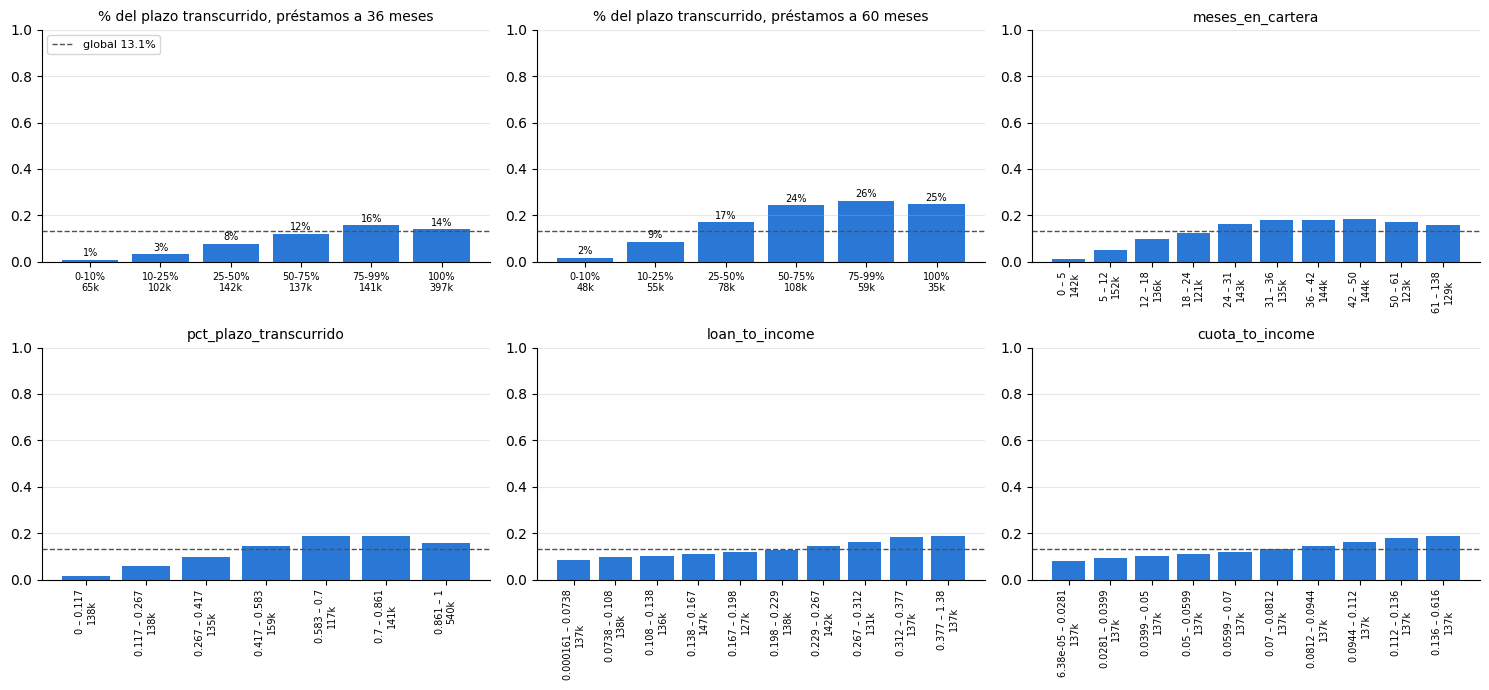

,meses_en_cartera,pct_plazo_transcurrido,loan_to_income,cuota_to_income,issue_date_year,loan_term_months,funded_amnt,monthly_payment,annual_income,interest_rate
meses_en_cartera,1.00,0.92,0.06,0.07,-0.98,0.01,0.00,0.01,-0.06,0.09
pct_plazo_transcurrido,0.92,1.00,-0.03,0.04,-0.91,-0.27,-0.11,-0.05,-0.09,-0.04
loan_to_income,0.06,-0.03,1.00,0.96,-0.06,0.34,0.62,0.61,-0.31,0.23
cuota_to_income,0.07,0.04,0.96,1.00,-0.07,0.10,0.53,0.59,-0.37,0.24


In [23]:
def tabla_train(clave, datos=None):
    """Como tabla_tasa (4.2), pero sobre train: tamaño, impagos y tasa de impago por grupo."""
    datos = train if datos is None else datos
    t = datos.groupby(clave, observed=True)["impago"].agg(n="size", n_impagos="sum", tasa_impago="mean")
    t.index.name = clave.name
    return t


def deciles_train(col):
    """Como tramos (4.2), pero sobre train: deciles con etiquetas legibles."""
    t = pd.qcut(train[col], q=10, duplicates="drop")
    fmt = lambda v: f"{v:,.0f}" if abs(v) >= 100 else f"{v:.3g}"
    minimo = train[col].min()
    return t.cat.rename_categories(
        [f"{fmt(max(iv.left, minimo))} – {fmt(iv.right)}" for iv in t.cat.categories]).rename(col)


# Tramos de madurez: el último ("100%") son los préstamos que ya han cumplido todo su plazo
madurez = pd.cut(train["pct_plazo_transcurrido"], [-0.01, 0.1, 0.25, 0.5, 0.75, 0.99, 1],
                 labels=["0-10%", "10-25%", "25-50%", "50-75%", "75-99%", "100%"]).rename("pct_plazo")

fig, axes = rejilla(6)
axes = list(axes)
for ax, plazo in zip(axes, (36, 60)):                 # arriba: madurez separada por plazo
    m = train["loan_term_months"] == plazo
    plot_tasa(ax, tabla_train(madurez[m], train[m]), f"% del plazo transcurrido, préstamos a {plazo} meses")
axes[0].legend(fontsize=8, loc="upper left")
for ax, col in zip(axes[2:], vars_nuevas):            # abajo: deciles de las 4 nuevas
    plot_tasa(ax, tabla_train(deciles_train(col)), col, etiquetas=False)
plt.tight_layout()
plt.show()

# Correlación de Spearman de las nuevas con las variables de las que salen
padres = ["issue_date_year", "loan_term_months", "funded_amnt", "monthly_payment", "annual_income", "interest_rate"]
train[vars_nuevas + padres].corr("spearman").loc[vars_nuevas].round(2)

## 6. Guardar los datos preparados

**Qué hace**: guarda train, validación y test, ya preparados, en `data/processed/`, junto con las listas de variables (`variables.json`). Son la entrada de `02_modelo_pd.ipynb` y de `03_ead_lgd_ecl.ipynb`.

- Se guardan **todas las columnas**, también las de performance: `03_ead_lgd_ecl.ipynb` las necesita para construir los targets de EAD y LGD. Solo se quitan los textos originales `emp_title` y `emp_length`, ya sustituidos por `emp_title_clean` y `emp_length_num`.
- Se guarda en **pickle** (`.pkl`), el formato nativo de pandas: conserva el **índice original** de cada préstamo y los tipos de las columnas sin instalar nada más (parquet necesitaría `pyarrow`). El índice es lo que permite, al final, emparejar la PD, la LGD y la EAD de cada préstamo.
- Así el split se hace **una sola vez**, y los dos notebooks siguientes usan exactamente los mismos préstamos en cada parte.

In [24]:
import json
import os

RUTA_DATOS = "data/processed"
os.makedirs(RUTA_DATOS, exist_ok=True)

for nombre, parte in (("train", train), ("val", val), ("test", test)):
    parte.drop(columns=["emp_title", "emp_length"]).to_pickle(f"{RUTA_DATOS}/{nombre}.pkl")

variables = {"continuas": continuas, "conteos": conteos, "categoricas": categoricas,
             "vars_nuevas": vars_nuevas, "performance": performance, "forbidden": forbidden}
with open(f"{RUTA_DATOS}/variables.json", "w", encoding="utf-8") as f:
    json.dump(variables, f, ensure_ascii=False, indent=1)

pd.DataFrame({"n_prestamos": [len(p) for p in (train, val, test)],
              "columnas": [p.shape[1] - 2 for p in (train, val, test)]},
             index=["train", "validación", "test"])

,n_prestamos,columnas
train,1369371,53
validación,342343,53
test,427929,53
